<a href="https://colab.research.google.com/github/francji1/01ADS/blob/main/lectures/L06_word2vec_transformers/01ADS_L06_Word2vec_Transformers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01ADS - Lecture 06: From words to vectors, word2vec and an introduction to transformers

Lecture 05 used embeddings that somebody else had trained (ResNet18, CLIP). Today we train one ourselves. Word2vec
is the simplest neural network that produces useful embeddings: one table of numbers, learned from raw text without
any labels, which we can then save and reuse for search, classification or recommendations.

Word2vec gives every word exactly one vector, whatever the context. The second half of the lecture shows how
**transformers** fix this with *attention*, and that "transformer" is not one model but a whole family:
encoders, decoders and encoder-decoders, with different training objectives, different uses and a history that
explains today's model zoo.

## Schedule for today's lecture
1. Words as numbers: one-hot vectors, an embedding layer is a lookup table, co-occurrence counts
2. Word2vec, the simplest network that learns embeddings: skip-gram, negative sampling, our own implementation in PyTorch, watching the vectors move during training
3. What the vectors learned: neighbours, analogies, an analogy benchmark, where it fails, a model trained on more text, pretrained GloVe
4. Using the vectors: sentence vectors by averaging, saving and loading, item2vec, limits (Czech word forms, one vector per word)
5. Transformers, one architecture and many models: tokenisation, self-attention by hand, encoder vs. decoder vs. encoder-decoder, attention inside a real model, history of the best-known models, what the best models can do compared with humans, state of the art by task
6. Summary and what comes next

Rough budget for 90 minutes: setup 5, section 1 8, section 2 20, section 3 12, section 4 8, transformers 5.1-5.4
22, history and leaderboards 5.5-5.7 12, summary 3. Subsections marked *(optional)* and the *Your turn* cells can be
skipped in the lecture without losing the thread.
If time is short, go through sections 5.6 and 5.7 (leaderboards, state of the art) only for the tasks relevant to
your project and read the rest at home.

## 0. Setup

**Start with *Runtime → Run all* at the beginning of the lecture.** The first run downloads about 1 GB: the text8
corpus (31 MB), pretrained GloVe vectors (128 MB), three small transformers (DistilBERT 260 MB, DistilGPT-2 340 MB,
T5-small 240 MB) and four tokenizers. A warning about a missing `HF_TOKEN` can be ignored.

Everything runs on a CPU, in Colab in about 5 minutes after the downloads. Our word2vec network is trained live on a
small part of the corpus (about a minute on a CPU); the same network trained on the whole corpus (17 million words,
three passes: a minute on a fast GPU, several minutes on a Colab T4, half an hour on a CPU) is downloaded from
`outputs/w2v_text8.npz`.

In [1]:
import importlib
import subprocess
import sys

for module, package in [("gensim", "gensim")]:
    try:
        importlib.import_module(module)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

In [2]:
import os

os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")

import collections
import contextlib
import io
import logging
import re
import time
import urllib.request
import warnings
import zipfile
from pathlib import Path

logging.getLogger("torch.distributed.elastic.multiprocessing.redirects").setLevel(logging.ERROR)   # Windows-only notice

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from gensim.models import KeyedVectors, Word2Vec
from gensim.test.utils import datapath
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import roc_auc_score
import transformers
from transformers import (AutoModelForCausalLM, AutoModelForMaskedLM, AutoModelForSeq2SeqLM, AutoTokenizer)
import huggingface_hub

transformers.utils.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
huggingface_hub.utils.logging.set_verbosity_error()
warnings.filterwarnings("ignore", category=FutureWarning)

SEED = 42
torch.manual_seed(SEED)
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_colwidth", 200)
unit = lambda v: v / np.linalg.norm(v)                  # vector of length 1
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"torch {torch.__version__}, transformers {transformers.__version__}, device: {device}")

torch 2.9.0+cu128, transformers 5.22.1, device: cuda


In [3]:
# Files of this lecture (and of Lecture 05) are read local-first and downloaded from GitHub when missing (Colab).
RAW = "https://raw.githubusercontent.com/francji1/01ADS/main/lectures"
OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)


def fetch(relpath: str, lecture: str = "L06_word2vec_transformers") -> Path:
    if lecture != "L06_word2vec_transformers":
        sibling = Path("..") / lecture / relpath         # the repository is cloned: use the other lecture's folder
        if sibling.exists():
            return sibling
        p = Path("tmp_data") / lecture / relpath           # not part of this lecture's folder (ignored by git)
    else:
        p = Path(relpath)
    if not p.exists():
        p.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{RAW}/{lecture}/{relpath}", p)
    return p


L05 = "L05_embeddings"

## 1. Words as numbers

A network computes with numbers, so every word has to become a vector. The simplest choice is **one-hot
encoding** (Lecture 03 used it for categorical variables): with a vocabulary of $V$ words, word number $i$ is the
vector of length $V$ with a single 1 at position $i$.

**Before running:** what is the cosine similarity of the one-hot vectors of *cat* and *dog*? And of *cat* and
*democracy*?

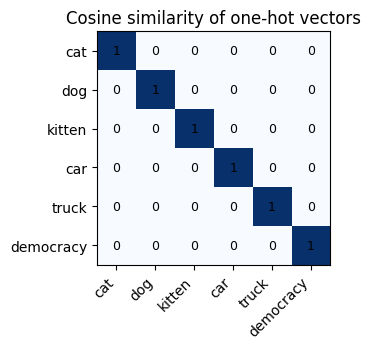

In [4]:
words = ["cat", "dog", "kitten", "car", "truck", "democracy"]
one_hot = np.eye(len(words))
cos_one_hot = one_hot @ one_hot.T            # rows have length 1, so the dot product is the cosine

fig, ax = plt.subplots(figsize=(4.2, 3.6))
ax.imshow(cos_one_hot, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(words)), words, rotation=45, ha="right")
ax.set_yticks(range(len(words)), words)
for i in range(len(words)):
    for j in range(len(words)):
        ax.text(j, i, f"{cos_one_hot[i, j]:.0f}", ha="center", va="center", fontsize=9)
ax.set_title("Cosine similarity of one-hot vectors")
plt.tight_layout()
plt.show()

Every two different words are orthogonal: *cat* is exactly as far from *kitten* as from *democracy*. The vectors are
also as long as the vocabulary (tens of thousands of numbers, almost all zero).

**An embedding layer** fixes both problems with a trainable matrix $W \in \mathbb{R}^{V \times d}$ with
$d \ll V$ (typically 50 to 1 000). The embedding of word $i$ is the product of its one-hot vector with $W$, which is
just row $i$ of $W$. Frameworks therefore do not multiply at all, they look the row up (`nn.Embedding`), but it is
still an ordinary linear layer and it is trained by backpropagation like any other.

In [5]:
V, d = len(words), 3
emb = nn.Embedding(V, d)                       # a V x d table with random initial values
i = words.index("dog")

via_lookup = emb(torch.tensor([i]))
via_matmul = F.one_hot(torch.tensor([i]), V).float() @ emb.weight
print("row of the table   :", via_lookup.detach().numpy().round(3))
print("one-hot x matrix   :", via_matmul.detach().numpy().round(3))
print("identical:", torch.allclose(via_lookup, via_matmul))

row of the table   : [[ 0.44  -0.758  1.078]]
one-hot x matrix   : [[ 0.44  -0.758  1.078]]
identical: True


The table starts random. What should training push it towards? The **distributional hypothesis** (Harris 1954,
Firth 1957): *"You shall know a word by the company it keeps."* Words that appear in similar contexts have similar
meanings. Even without a network we can count which words appear next to which and compare the rows of the count
matrix. Count matrices compressed by SVD (word × document counts in latent semantic analysis, 1990; word × word
windows later) were the embeddings before word2vec.

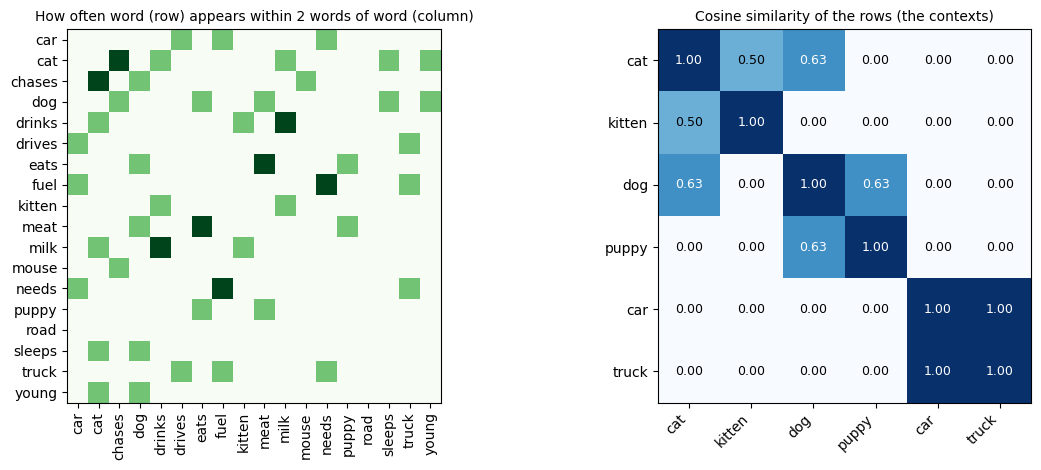

In [6]:
toy_corpus = [
    "the cat drinks milk", "the kitten drinks milk", "the dog eats meat", "the puppy eats meat",
    "the cat chases the mouse", "the dog chases the cat", "a kitten is a young cat", "a puppy is a young dog",
    "the car drives on the road", "the truck drives on the road", "the car needs fuel", "the truck needs fuel",
    "the dog sleeps in the car", "the cat sleeps in the truck",
]
toy_tokens = [s.split() for s in toy_corpus]
stop = {"the", "a", "is", "on", "in"}
toy_vocab = sorted({w for s in toy_tokens for w in s} - stop)
idx = {w: k for k, w in enumerate(toy_vocab)}
counts = np.zeros((len(toy_vocab), len(toy_vocab)))
for s in toy_tokens:
    for a, wa in enumerate(s):
        for b in range(max(0, a - 2), min(len(s), a + 3)):          # window of 2 words on each side, stop words count
            if b != a and wa in idx and s[b] in idx:                  # as positions but are not counted themselves
                counts[idx[wa], idx[s[b]]] += 1

nouns = ["cat", "kitten", "dog", "puppy", "car", "truck"]
rows = np.stack([counts[idx[w]] for w in nouns])
rows = rows / np.linalg.norm(rows, axis=1, keepdims=True)
cos_counts = rows @ rows.T

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
axes[0].imshow(counts, cmap="Greens")
axes[0].set_xticks(range(len(toy_vocab)), toy_vocab, rotation=90)
axes[0].set_yticks(range(len(toy_vocab)), toy_vocab)
axes[0].set_title("How often word (row) appears within 2 words of word (column)", fontsize=10)
im = axes[1].imshow(cos_counts, cmap="Blues", vmin=0, vmax=1)
axes[1].set_xticks(range(len(nouns)), nouns, rotation=45, ha="right")
axes[1].set_yticks(range(len(nouns)), nouns)
for i in range(len(nouns)):
    for j in range(len(nouns)):
        axes[1].text(j, i, f"{cos_counts[i, j]:.2f}", ha="center", va="center", fontsize=9,
                     color="white" if cos_counts[i, j] > 0.6 else "black")
axes[1].set_title("Cosine similarity of the rows (the contexts)", fontsize=10)
plt.tight_layout()
plt.show()

Already on fourteen sentences the context rows of *cat* and *kitten*, or *car* and *truck*, are similar, while
animals and vehicles are not, although nobody told the method what an animal or a vehicle is. Compare it with the
one-hot matrix above, where every pair had similarity 0. Word2vec learns the same kind of geometry, but with a network that
scales to billions of words and produces better vectors.

## 2. Word2vec, the simplest network that learns embeddings

Word2vec (Mikolov et al., Google, 2013) turns the distributional hypothesis into a prediction task with free
labels: slide a window over the text and, for each **centre word**, predict the words around it (its **context**).

- **Skip-gram:** centre word → each context word. Better for rare words, the variant we implement.
- **CBOW** (continuous bag of words): average of the context words → centre word. Faster.

The network has no hidden non-linearity at all: an input embedding table, an output embedding table and a dot
product. After training we throw the task away and keep the input table: those are the word vectors.

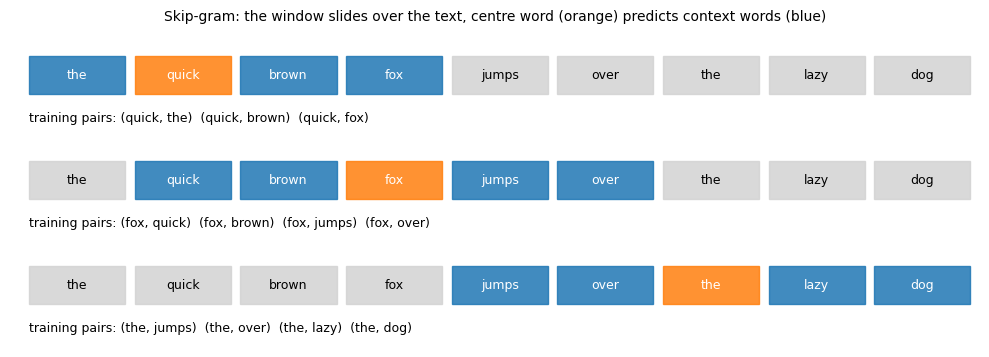

In [7]:
def draw_window(ax, sentence, centre, window=2):
    toks = sentence.split()
    for k, w in enumerate(toks):
        if k == centre:
            colour = "tab:orange"
        elif abs(k - centre) <= window:
            colour = "tab:blue"
        else:
            colour = "lightgrey"
        ax.add_patch(plt.Rectangle((k * 1.1, 0), 1.0, 0.8, color=colour, alpha=0.85))
        ax.text(k * 1.1 + 0.5, 0.4, w, ha="center", va="center", fontsize=9,
                color="white" if colour != "lightgrey" else "black")
    pairs = [f"({toks[centre]}, {toks[k]})" for k in range(max(0, centre - window), min(len(toks), centre + window + 1))
             if k != centre]
    ax.text(0, -0.5, "training pairs: " + "  ".join(pairs), fontsize=9, va="center")
    ax.set_xlim(-0.2, len(toks) * 1.1)
    ax.set_ylim(-0.9, 1.0)
    ax.axis("off")


sentence = "the quick brown fox jumps over the lazy dog"
fig, axes = plt.subplots(3, 1, figsize=(10, 3.6))
for ax, c in zip(axes, [1, 3, 6]):
    draw_window(ax, sentence, c)
fig.suptitle("Skip-gram: the window slides over the text, centre word (orange) predicts context words (blue)", fontsize=10)
plt.tight_layout()
plt.show()

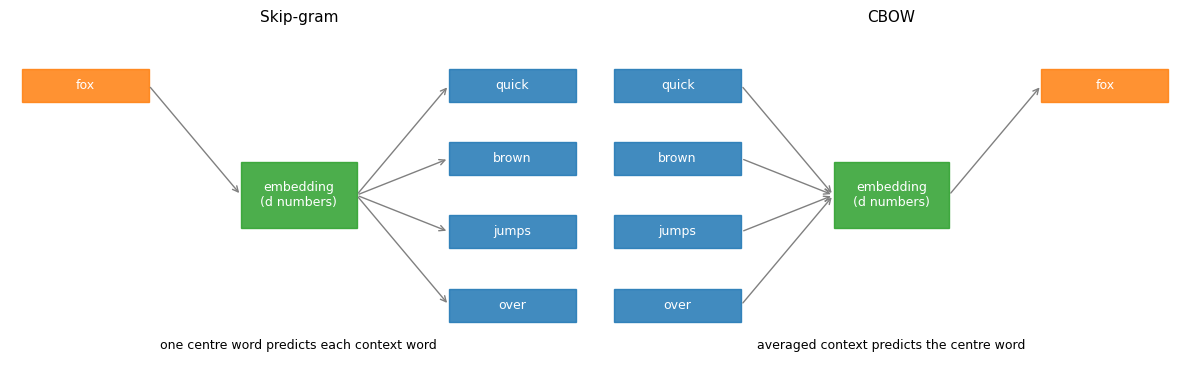

In [8]:
def draw_architecture(ax, title, inputs, output, note):
    ax.set_xlim(0, 10)
    ax.set_ylim(0, 6)
    ax.axis("off")
    ax.set_title(title, fontsize=11)
    ys = np.linspace(5, 1, len(inputs))
    for y, w in zip(ys, inputs):
        ax.add_patch(plt.Rectangle((0.2, y - 0.3), 2.2, 0.6, color="tab:orange" if len(inputs) == 1 else "tab:blue", alpha=0.85))
        ax.text(1.3, y, w, ha="center", va="center", color="white", fontsize=9)
        ax.annotate("", xy=(4.0, 3), xytext=(2.4, y), arrowprops=dict(arrowstyle="->", color="grey"))
    ax.add_patch(plt.Rectangle((4.0, 2.4), 2.0, 1.2, color="tab:green", alpha=0.85))
    ax.text(5.0, 3, "embedding\n(d numbers)", ha="center", va="center", color="white", fontsize=9)
    outs = output if isinstance(output, list) else [output]
    ys = np.linspace(5, 1, len(outs))
    for y, w in zip(ys, outs):
        ax.annotate("", xy=(7.6, y), xytext=(6.0, 3), arrowprops=dict(arrowstyle="->", color="grey"))
        ax.add_patch(plt.Rectangle((7.6, y - 0.3), 2.2, 0.6, color="tab:blue" if len(outs) > 1 else "tab:orange", alpha=0.85))
        ax.text(8.7, y, w, ha="center", va="center", color="white", fontsize=9)
    ax.text(5, 0.2, note, ha="center", fontsize=9)


fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
draw_architecture(axes[0], "Skip-gram", ["fox"], ["quick", "brown", "jumps", "over"], "one centre word predicts each context word")
draw_architecture(axes[1], "CBOW", ["quick", "brown", "jumps", "over"], "fox", "averaged context predicts the centre word")
plt.tight_layout()
plt.show()

### Negative sampling

Predicting the context word with a softmax over the whole vocabulary would mean computing $V$ scores (tens of
thousands) for every training pair. **Negative sampling** replaces the softmax by a binary task: is this pair a
real (centre, context) pair from the text, or a random fake? For a real pair $(c, o)$ and $K$ random "negative"
words $n_1, \dots, n_K$ the loss is

$$\mathcal{L} = -\log \sigma(\mathbf{u}_o^\top \mathbf{v}_c) - \sum_{k=1}^{K} \log \sigma(-\mathbf{u}_{n_k}^\top \mathbf{v}_c),$$

where $\mathbf{v}$ are rows of the input table, $\mathbf{u}$ rows of the output table and $\sigma$ the logistic
function. Real pairs are pushed to a large dot product, random pairs to a small one. This is the same idea as the
contrastive loss of CLIP in Lecture 05 (true pairs vs. random ones), eight years earlier and for words; negative
sampling scores each pair with a sigmoid (like SigLIP), instead of CLIP's softmax over the whole batch.

Two practical tricks from the paper:

- negatives are drawn with probability proportional to $\text{count}^{0.75}$, which gives rare words more chances
  than their raw frequency would,
- very frequent words (*the*, *of*) are randomly dropped from the text (**subsampling**): they carry little
  information and would otherwise produce most of the pairs. A token of a word with relative frequency $f(w)$ is
  kept with probability $\min\!\big(1, \sqrt{t/f(w)} + t/f(w)\big)$, $t = 10^{-4}$ (the formula of the original
  word2vec code).

### The data: text8

text8 is the first 100 million characters of English Wikipedia (2006), lower-cased, without punctuation: about 17
million words. It is the standard small corpus for word2vec experiments.

In [9]:
TEXT8 = Path("tmp_data/text8.zip")          # 31 MB, downloaded once, not part of the repository
if TEXT8.exists():
    corpus = zipfile.ZipFile(TEXT8).read("text8").decode().split()
else:
    try:
        TEXT8.parent.mkdir(exist_ok=True)
        urllib.request.urlretrieve("https://mattmahoney.net/dc/text8.zip", TEXT8)
        corpus = zipfile.ZipFile(TEXT8).read("text8").decode().split()
    except OSError as e:                              # backup: the same corpus from the gensim data repository
        print("mattmahoney.net failed, using gensim-data:", e)
        import gensim.downloader as api
        corpus = [w for chunk in api.load("text8") for w in chunk]
print(f"{len(corpus):,} words, {len(set(corpus)):,} distinct")
print(" ".join(corpus[:60]))

17,005,207 words, 253,854 distinct
anarchism originated as a term of abuse first used against early working class radicals including the diggers of the english revolution and the sans culottes of the french revolution whilst the term is still used in a pejorative way to describe any act that used violent means to destroy the organization of society it has also been taken up as


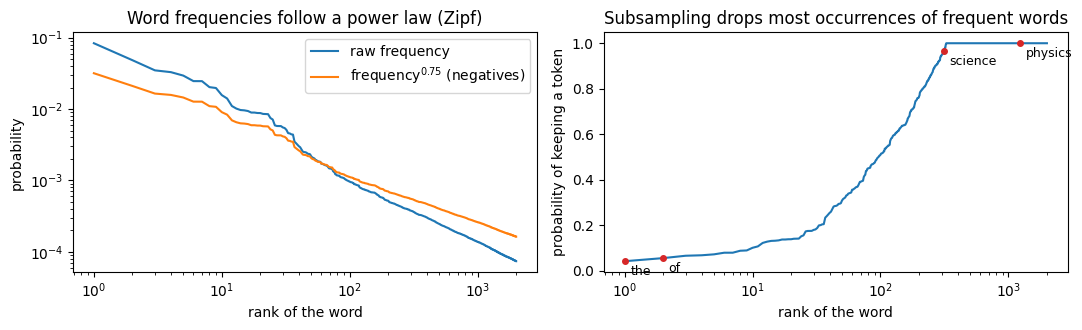

In [10]:
def build_vocab(tokens, max_size=30_000, min_count=5):
    cnt = collections.Counter(tokens)
    vocab = [w for w, c in cnt.most_common(max_size) if c >= min_count]
    freq = np.array([cnt[w] for w in vocab], dtype=np.float64)
    return vocab, {w: k for k, w in enumerate(vocab)}, freq


def make_pairs(ids, freq, window, rng, t=1e-4):
    # subsampling of frequent words, then all (centre, context) pairs with a random window size 1..window
    f = freq / freq.sum()
    p_keep = np.minimum(1.0, np.sqrt(t / f) + t / f)
    kept = ids[rng.random(len(ids)) < p_keep[ids]]
    win = rng.integers(1, window + 1, size=len(kept))
    centre, context = [], []
    for off in range(1, window + 1):
        pos = np.nonzero(win >= off)[0]
        right = pos[pos + off < len(kept)]
        left = pos[pos - off >= 0]
        centre += [kept[right], kept[left]]
        context += [kept[right + off], kept[left - off]]
    centre, context = np.concatenate(centre), np.concatenate(context)
    perm = rng.permutation(len(centre))
    return torch.from_numpy(centre[perm]), torch.from_numpy(context[perm])


freq_demo = collections.Counter(corpus[:2_000_000])
top = np.array([c for _, c in freq_demo.most_common(2000)], dtype=float)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].loglog(np.arange(1, len(top) + 1), top / top.sum(), label="raw frequency")
axes[0].loglog(np.arange(1, len(top) + 1), top**0.75 / (top**0.75).sum(), label="frequency$^{0.75}$ (negatives)")
axes[0].set_xlabel("rank of the word")
axes[0].set_ylabel("probability")
axes[0].set_title("Word frequencies follow a power law (Zipf)")
axes[0].legend()
f = top / sum(freq_demo.values())
axes[1].semilogx(np.arange(1, len(top) + 1), np.minimum(1, np.sqrt(1e-4 / f) + 1e-4 / f))
for w in ["the", "of", "science", "physics"]:
    r = [x for x, _ in freq_demo.most_common(2000)].index(w) + 1 if w in dict(freq_demo.most_common(2000)) else None
    if r:
        pk = min(1, np.sqrt(1e-4 / f[r - 1]) + 1e-4 / f[r - 1])
        axes[1].annotate(w, (r, pk), xytext=(4, -10), textcoords="offset points", fontsize=9)
        axes[1].plot(r, pk, "o", color="tab:red", ms=4)
axes[1].set_xlabel("rank of the word")
axes[1].set_ylabel("probability of keeping a token")
axes[1].set_title("Subsampling drops most occurrences of frequent words")
plt.tight_layout()
plt.show()

### Our own word2vec in PyTorch

The whole model is two embedding tables and the loss from above.

In [11]:
class SkipGram(nn.Module):
    def __init__(self, vocab_size, dim):
        super().__init__()
        self.inp = nn.Embedding(vocab_size, dim)          # centre words: these become the word vectors
        self.out = nn.Embedding(vocab_size, dim)          # context words: used only during training
        nn.init.uniform_(self.inp.weight, -0.5 / dim, 0.5 / dim)
        nn.init.zeros_(self.out.weight)

    def forward(self, centre, context, negatives):
        v = self.inp(centre)                                            # (B, d)
        pos = (v * self.out(context)).sum(-1)                           # (B,)   scores of the real pairs
        neg = torch.bmm(self.out(negatives), v.unsqueeze(-1)).squeeze(-1)   # (B, K) scores of the fake pairs
        return -(F.logsigmoid(pos) + F.logsigmoid(-neg).sum(-1)).mean()


def train_skipgram(tokens, dim=100, window=5, negatives=5, epochs=1, batch=16_384, lr=1e-2,
                   track=(), n_snapshots=0, seed=SEED):
    rng = np.random.default_rng(seed)
    torch.manual_seed(seed)
    vocab, w2i, freq = build_vocab(tokens)
    ids = np.array([w2i[w] for w in tokens if w in w2i])
    noise = torch.tensor(freq**0.75 / (freq**0.75).sum(), dtype=torch.float, device=device)
    model = SkipGram(len(vocab), dim).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    track_ids = [w2i[w] for w in track if w in w2i]
    losses, snapshots = [], []
    for ep in range(epochs):
        centre, context = make_pairs(ids, freq, window, rng)
        n_batches = (len(centre) + batch - 1) // batch
        snap_at = set(np.linspace(0, n_batches - 1, n_snapshots).astype(int)) if n_snapshots else set()
        for b in range(n_batches):
            c = centre[b * batch:(b + 1) * batch].to(device)
            o = context[b * batch:(b + 1) * batch].to(device)
            if b in snap_at:                              # snapshot before the update (the first one = random start)
                snapshots.append(model.inp.weight[track_ids].detach().cpu().numpy().copy())
            neg = torch.multinomial(noise, len(c) * negatives, replacement=True).view(len(c), negatives)
            loss = model(c, o, neg)
            opt.zero_grad()
            loss.backward()
            opt.step()
            losses.append(loss.item())
        print(f"epoch {ep + 1}: {len(centre):,} pairs, mean loss {np.mean(losses[-n_batches:]):.3f}")
    vectors = model.inp.weight.detach().cpu().numpy()
    return vocab, vectors, np.array(losses), np.array(snapshots), [w for w in track if w in w2i]

**Live training.** First 2 million words of text8 (an eighth of the corpus), one pass: seconds on a GPU, about a
minute on a Colab CPU. We follow the vectors of a few groups of words during training.

**Before running:** the vectors start random. Which groups do you expect to come together first?

epoch 1: 6,175,747 pairs, mean loss 2.557
vocabulary 21,681 words, training took 4 s on cuda


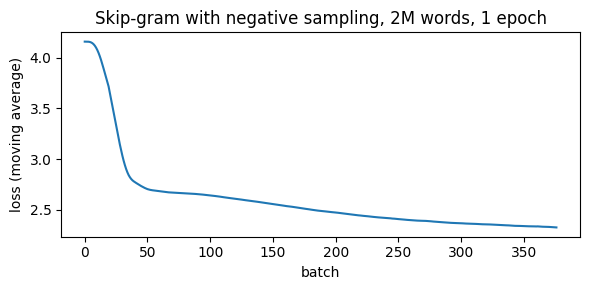

In [12]:
groups = {
    "numbers": ["one", "two", "three", "four", "five", "six", "seven"],
    "countries": ["france", "germany", "italy", "spain", "england", "russia", "china"],
    "colours": ["red", "blue", "green", "yellow", "black", "white"],
    "family": ["father", "mother", "son", "daughter", "brother", "sister", "wife"],
    "science": ["physics", "chemistry", "mathematics", "biology", "theory", "energy"],
}
track = [w for ws in groups.values() for w in ws]
colour_of = {w: f"C{k}" for k, ws in enumerate(groups.values()) for w in ws}

t0 = time.time()
small_vocab, small_vectors, small_losses, snapshots, tracked = train_skipgram(
    corpus[:2_000_000], epochs=1, track=track, n_snapshots=8)
print(f"vocabulary {len(small_vocab):,} words, training took {time.time() - t0:.0f} s on {device}")

plt.figure(figsize=(6, 3))
plt.plot(pd.Series(small_losses).rolling(20, min_periods=1).mean())
plt.xlabel("batch")
plt.ylabel("loss (moving average)")
plt.title("Skip-gram with negative sampling, 2M words, 1 epoch")
plt.tight_layout()
plt.show()

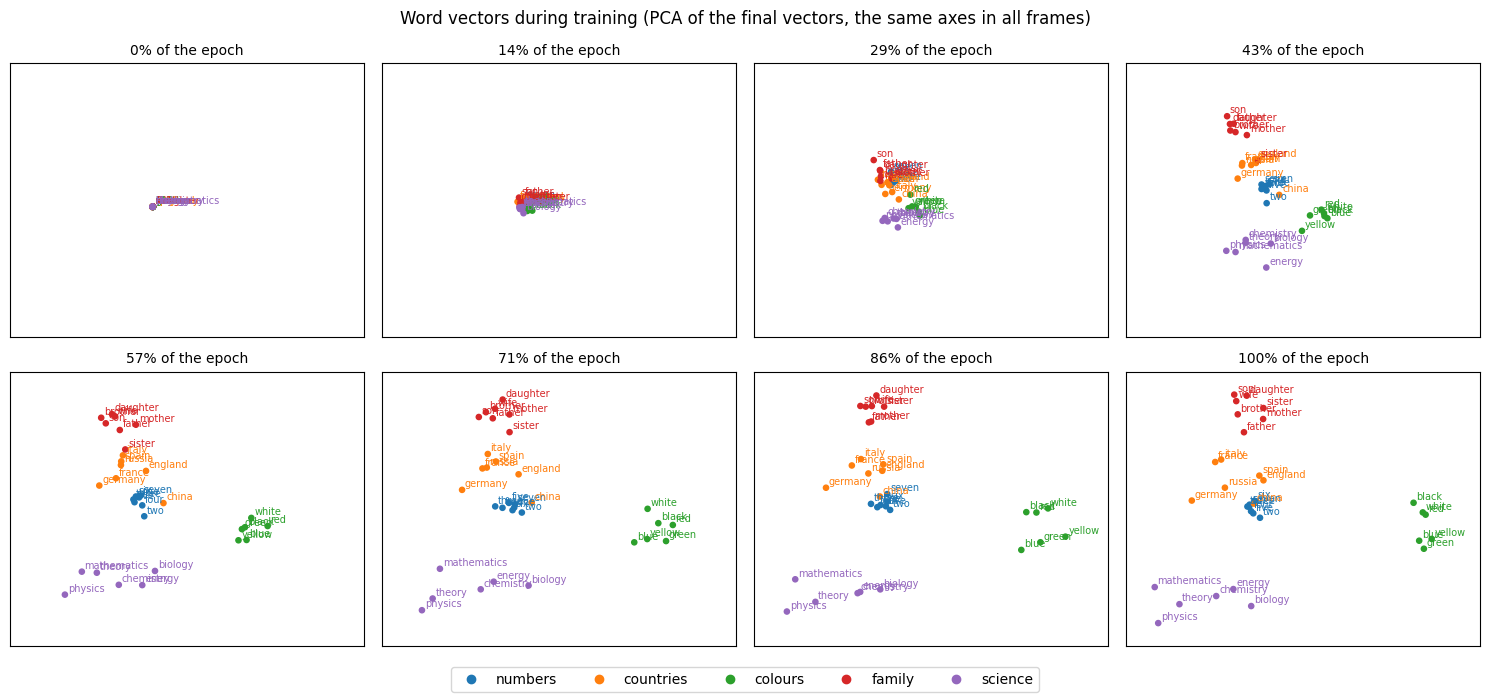

In [13]:
# One PCA fitted on the final vectors and applied to every snapshot, so that the frames are comparable.
pca = PCA(2).fit(snapshots[-1])
frames = [pca.transform(snap) for snap in snapshots]
lo, hi = np.min([f.min(0) for f in frames], 0), np.max([f.max(0) for f in frames], 0)
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for k, (ax, xy) in enumerate(zip(axes.ravel(), frames)):
    ax.scatter(xy[:, 0], xy[:, 1], c=[colour_of[w] for w in tracked], s=14)
    for w, (x, y) in zip(tracked, xy):
        ax.annotate(w, (x, y), fontsize=7, color=colour_of[w], xytext=(2, 2), textcoords="offset points")
    ax.set_title(f"{k / (len(snapshots) - 1):.0%} of the epoch", fontsize=10)
    ax.set_xlim(lo[0] - 0.1 * (hi[0] - lo[0]), hi[0] + 0.15 * (hi[0] - lo[0]))
    ax.set_ylim(lo[1] - 0.1 * (hi[1] - lo[1]), hi[1] + 0.1 * (hi[1] - lo[1]))
    ax.set_xticks([])
    ax.set_yticks([])
handles = [plt.Line2D([], [], marker="o", ls="", color=f"C{k}", label=g) for k, g in enumerate(groups)]
fig.legend(handles=handles, loc="lower center", ncol=len(groups))
fig.suptitle("Word vectors during training (PCA of the final vectors, the same axes in all frames)")
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

Nobody told the network that *three* is a number or *france* a country. The groups appear only because such words
occur in similar contexts. Frequent words with very regular contexts (numbers, colours) separate first; the rest
of the epoch mostly tightens the groups.

In [14]:
def nearest(word, vocab, vectors, k=6):
    w2i = {w: i for i, w in enumerate(vocab)}
    if word not in w2i:
        return "(not in vocabulary)"
    unit = vectors / np.linalg.norm(vectors, axis=1, keepdims=True)
    sims = unit @ unit[w2i[word]]
    best = np.argsort(-sims)[1:k + 1]
    return ", ".join(f"{vocab[j]} {sims[j]:.2f}" for j in best)


probe = ["three", "france", "red", "father", "physics", "king", "computer", "dog"]
pd.DataFrame({"word": probe, "nearest words (2M words, 1 epoch)": [nearest(w, small_vocab, small_vectors) for w in probe]})

,word,"nearest words (2M words, 1 epoch)"
0,three,"five 0.87, four 0.86, two 0.85, six 0.79, zero 0.79, kf 0.79"
1,france,"poitou 0.75, cadiz 0.74, italy 0.72, clermont 0.71, lisbon 0.69, vichy 0.67"
2,red,"white 0.70, cross 0.66, sleeves 0.62, yellow 0.62, purple 0.62, jerseys 0.61"
3,father,"son 0.80, hversu 0.77, achimelech 0.77, almighty 0.75, begotten 0.75, fathered 0.75"
4,physics,"quantum 0.77, theoretical 0.75, electromagnetism 0.74, brownian 0.73, experimentally 0.73, cosmology 0.73"
5,king,"epirus 0.80, consort 0.79, surnamed 0.78, agathocles 0.78, anjou 0.77, demetrius 0.76"
6,computer,"computers 0.86, gui 0.80, machines 0.78, emulated 0.77, powerpc 0.77, graphical 0.76"
7,dog,"eat 0.66, stray 0.62, giant 0.60, sheep 0.60, whale 0.60, kilgore 0.59"


### The same network trained on the whole corpus

Two million words and one pass give recognisable but noisy neighbours. The same code on all 17 million words for
three epochs takes about a minute on a fast GPU and several minutes on a Colab T4, so the result is downloaded from
`outputs/w2v_text8.npz`. Set `RETRAIN = True` (with a GPU) to train it yourself.

In [15]:
w2v_file = OUT_DIR / "w2v_text8.npz"
RETRAIN = False
if not RETRAIN:
    try:
        fetch(w2v_file.as_posix())
    except OSError as e:
        print("download failed, the model will be trained:", e)
if RETRAIN or not w2v_file.exists():
    if device.type != "cuda":
        raise RuntimeError("The pretrained vectors could not be downloaded and training on a CPU takes about half an "
                           "hour. Re-run this cell, or switch to a GPU runtime (Runtime -> Change runtime type).")
    t0 = time.time()
    full_vocab, full_vectors, full_losses, _, _ = train_skipgram(corpus, epochs=3)
    print(f"trained in {time.time() - t0:.0f} s on {device}")
    np.savez_compressed(w2v_file, vocab=np.array(full_vocab), vectors=full_vectors.astype(np.float16),
                        losses=full_losses.astype(np.float32))
z = np.load(w2v_file)
full_vocab, full_vectors = [str(w) for w in z["vocab"]], z["vectors"].astype(np.float32)
print(f"full model: {len(full_vocab):,} words x {full_vectors.shape[1]} dimensions, file {w2v_file.stat().st_size / 1e6:.1f} MB")

pd.DataFrame({"word": probe,
              "2M words, 1 epoch": [nearest(w, small_vocab, small_vectors, 5) for w in probe],
              "17M words, 3 epochs": [nearest(w, full_vocab, full_vectors, 5) for w in probe]})

full model: 30,000 words x 100 dimensions, file 5.8 MB


,word,"2M words, 1 epoch","17M words, 3 epochs"
0,three,"five 0.87, four 0.86, two 0.85, six 0.79, zero 0.79","one 0.90, four 0.90, two 0.89, eight 0.89, five 0.89"
1,france,"poitou 0.75, cadiz 0.74, italy 0.72, clermont 0.71, lisbon 0.69","belgium 0.71, netherlands 0.68, paris 0.68, spain 0.66, french 0.65"
2,red,"white 0.70, cross 0.66, sleeves 0.62, yellow 0.62, purple 0.62","blue 0.77, white 0.70, yellow 0.67, black 0.63, green 0.62"
3,father,"son 0.80, hversu 0.77, achimelech 0.77, almighty 0.75, begotten 0.75","son 0.82, mother 0.79, wife 0.75, daughter 0.73, brother 0.72"
4,physics,"quantum 0.77, theoretical 0.75, electromagnetism 0.74, brownian 0.73, experimentally 0.73","physicists 0.69, einstein 0.69, quantum 0.68, theoretical 0.68, mechanics 0.68"
5,king,"epirus 0.80, consort 0.79, surnamed 0.78, agathocles 0.78, anjou 0.77","throne 0.70, prince 0.68, son 0.68, kings 0.66, queen 0.64"
6,computer,"computers 0.86, gui 0.80, machines 0.78, emulated 0.77, powerpc 0.77","hardware 0.72, computers 0.72, computing 0.67, interface 0.67, software 0.65"
7,dog,"eat 0.66, stray 0.62, giant 0.60, sheep 0.60, whale 0.60","hound 0.61, wolf 0.58, dogs 0.57, terrier 0.56, shepherd 0.55"


## 3. What the vectors learned

### Analogies

The famous property of word2vec: differences of vectors encode relations. If *king* − *man* ≈ *queen* − *woman*,
then *king* − *man* + *woman* should land near *queen*. We look for the nearest word (excluding the three inputs)
by cosine similarity.

For comparison we load **GloVe** (Stanford, 2014): a different algorithm that fits the word vectors to the
logarithms of global co-occurrence counts (the statistics of our toy example in section 1) trained on 6 billion words of Wikipedia and news, the most used
pretrained word vectors of the 2010s.

**Before running:** which of the analogies below do you expect to fail, and why?

In [16]:
with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
    import gensim.downloader as api
    glove = api.load("glove-wiki-gigaword-100")       # 400 000 words x 100 dimensions, 128 MB

w2v = KeyedVectors(full_vectors.shape[1])
w2v.add_vectors(full_vocab, full_vectors)             # gensim wrapper around our table: same vectors, handy methods


def analogy(kv, a, b, c, topn=3):
    # a is to b as c is to ?   ->   b - a + c
    try:
        return ", ".join(f"{w} {s:.2f}" for w, s in kv.most_similar(positive=[b, c], negative=[a], topn=topn))
    except KeyError as e:
        return f"(missing word {e})"


tests = [("man", "king", "woman"), ("france", "paris", "italy"), ("france", "paris", "japan"),
         ("big", "bigger", "small"), ("good", "better", "bad"), ("walk", "walked", "go"),
         ("einstein", "physics", "darwin"), ("man", "actor", "woman")]
pd.DataFrame({"a : b = c : ?": [f"{a} : {b} = {c} : ?" for a, b, c in tests],
              "our word2vec, 17M words (top 3)": [analogy(w2v, *t) for t in tests],
              "GloVe, 6B words (top 3)": [analogy(glove, *t) for t in tests]})

,a : b = c : ?,"our word2vec, 17M words (top 3)","GloVe, 6B words (top 3)"
0,man : king = woman : ?,"throne 0.62, queen 0.58, heir 0.57","queen 0.77, monarch 0.68, throne 0.68"
1,france : paris = italy : ?,"bologna 0.65, rome 0.64, venice 0.59","rome 0.82, milan 0.74, naples 0.71"
2,france : paris = japan : ?,"tokyo 0.64, chiang 0.55, japanese 0.55","tokyo 0.90, osaka 0.74, japanese 0.71"
3,big : bigger = small : ?,"smaller 0.56, larger 0.55, size 0.52","larger 0.89, smaller 0.87, large 0.79"
4,good : better = bad : ?,"less 0.51, vastly 0.47, propeller 0.47","worse 0.84, too 0.75, even 0.73"
5,walk : walked = go : ?,"got 0.51, happened 0.47, beaten 0.47","went 0.84, came 0.79, out 0.79"
6,einstein : physics = darwin : ?,"biology 0.61, geology 0.60, zoology 0.56","science 0.60, botany 0.58, biology 0.55"
7,man : actor = woman : ?,"actress 0.72, singer 0.70, politician 0.66","actress 0.91, comedian 0.69, actresses 0.68"


Even the famous *king − man + woman* puts *queen* only second in our model (17 million words is little text);
GloVe gets it right. Irregular forms (*worse*, *went*) fail more often than regular ones (*smaller*): each irregular
form is a separate, rarer word, so its vector is noisier.

### Relations as directions *(optional)*

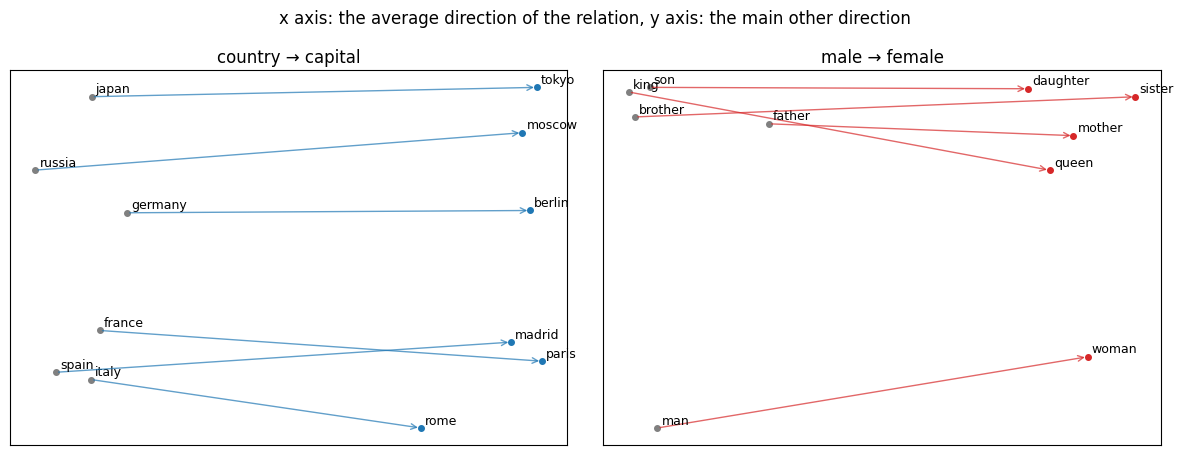

country -> capital mean cosine between the difference vectors: 0.37
male -> female     mean cosine between the difference vectors: 0.25
random pairs       mean cosine between the difference vectors: -0.02


In [17]:
pairs_plot = [("france", "paris"), ("germany", "berlin"), ("italy", "rome"), ("spain", "madrid"),
              ("russia", "moscow"), ("japan", "tokyo"), ("man", "woman"), ("king", "queen"),
              ("father", "mother"), ("son", "daughter"), ("brother", "sister")]


def relation_plane(sub):
    # x = the average direction of the relation, y = the main remaining direction among the words
    ws = [w for p in sub for w in p]
    X = np.stack([unit(w2v[w]) for w in ws])
    u = unit(np.mean([unit(w2v[b]) - unit(w2v[a]) for a, b in sub], axis=0))
    rest = X - np.outer(X @ u, u)
    v = PCA(1).fit(rest).components_[0]
    return dict(zip(ws, np.c_[X @ u, X @ v]))


fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, sub, col in [(axes[0], pairs_plot[:6], "tab:blue"), (axes[1], pairs_plot[6:], "tab:red")]:
    sp = relation_plane(sub)
    for a, b in sub:
        ax.annotate("", xy=sp[b], xytext=sp[a], arrowprops=dict(arrowstyle="->", color=col, alpha=0.7))
        for w in (a, b):
            ax.annotate(w, sp[w], fontsize=9, xytext=(3, 3), textcoords="offset points")
        ax.plot(*sp[a], "o", color="grey", ms=4)
        ax.plot(*sp[b], "o", color=col, ms=4)
    ax.set_xticks([])
    ax.set_yticks([])
axes[0].set_title("country → capital")
axes[1].set_title("male → female")
fig.suptitle("x axis: the average direction of the relation, y axis: the main other direction")
plt.tight_layout()
plt.show()

# How parallel are the arrows, compared with arrows between random words?
diffs = lambda sub: np.stack([unit(unit(w2v[b]) - unit(w2v[a])) for a, b in sub])
rng = np.random.default_rng(SEED)
random_pairs = [tuple(rng.choice(full_vocab[:5000], 2)) for _ in range(6)]
for name, sub in [("country -> capital", pairs_plot[:6]), ("male -> female", pairs_plot[6:]), ("random pairs", random_pairs)]:
    c = diffs(sub) @ diffs(sub).T
    print(f"{name:18s} mean cosine between the difference vectors: {c[np.triu_indices(len(sub), 1)].mean():.2f}")

The horizontal axis is chosen as the average direction of each relation, so the arrows point to the right by
construction. The real test is the printed numbers: difference vectors of the same relation have a clearly
positive cosine with each other, while differences of random word pairs are orthogonal (cosine about 0). The
arrows are far from perfectly parallel, but far from random; that is enough for the nearest-word search of an
analogy to often land on the right answer.

### Measuring it: the Google analogy benchmark

The original paper came with about 19 500 analogy questions in 14 categories (capitals, currencies, family,
comparatives, past tense, ...). Accuracy = how often the nearest word is exactly the right answer. To compare the
three models fairly, we keep only the questions whose four words are among the most frequent words of all three
models, and each model searches for the answer among its 30 000 most frequent words.

In [18]:
small_kv = KeyedVectors(small_vectors.shape[1])
small_kv.add_vectors(small_vocab, small_vectors)

common = set(small_vocab) & set(full_vocab[:30_000]) & set(glove.index_to_key[:30_000])
with open(datapath("questions-words.txt")) as f:
    kept = [line for line in f if line.startswith(":") or all(w.lower() in common for w in line.split())]
questions = "tmp_questions.txt"                         # the common subset of questions (not part of the repository)
Path(questions).write_text("".join(kept))


def analogy_score(kv):
    # sections 0-4 are semantic (capitals, currency, family), 5-13 syntactic, the last one is the total
    _, sections = kv.evaluate_word_analogies(questions, restrict_vocab=30_000)
    n = lambda ss: sum(len(s["correct"]) + len(s["incorrect"]) for s in ss)
    acc = lambda ss: 100 * sum(len(s["correct"]) for s in ss) / max(1, n(ss))
    return {"semantic %": acc(sections[:5]), "syntactic %": acc(sections[5:-1]), "total %": acc(sections[-1:]),
            "questions evaluated": n(sections[-1:])}


analogy_table = pd.DataFrame({
    "ours, 2M words, 1 epoch": analogy_score(small_kv),
    "ours, 17M words, 3 epochs": analogy_score(w2v),
    "GloVe, 6B words": analogy_score(glove),
}).T.round(1)
analogy_table["questions evaluated"] = analogy_table["questions evaluated"].astype(int)
analogy_table

,semantic %,syntactic %,total %,questions evaluated
"ours, 2M words, 1 epoch",6.6,4.3,4.9,8668
"ours, 17M words, 3 epochs",29.9,25.3,26.5,8668
"GloVe, 6B words",61.8,70.8,68.6,8668


For analogies, the amount of text dominates. The same few lines of code go from almost nothing to a usable model
with eight times more words (and three passes instead of one), and GloVe, trained on 350 times more words, is far
better still. Most of that last gap is data, not the algorithm: word2vec and GloVe trained on the same billions of
words with comparably tuned settings score about the same (Levy, Goldberg and Dagan 2015).

### Where it fails *(optional)*

- **Antonyms** appear in the same contexts (*hot water*, *cold water*), so they get similar vectors.
- **Rare words** have few contexts and noisy vectors; words below the frequency cut-off get no vector at all.
- **Analogies** work best for relations with many examples in the text (capitals); the benchmark itself hides that
  the input words are excluded from the answer, otherwise *king − man + woman* would often return *king*.

In [19]:
for a, b in [("hot", "cold"), ("hot", "warm"), ("good", "bad"), ("good", "nice"), ("increase", "decrease")]:
    print(f"cos({a}, {b}) = {w2v.similarity(a, b):.2f}  (GloVe {glove.similarity(a, b):.2f})")
print("odd one out of breakfast, lunch, dinner, chair:", w2v.doesnt_match(["breakfast", "lunch", "dinner", "chair"]))

cos(hot, cold) = 0.59  (GloVe 0.73)
cos(hot, warm) = 0.61  (GloVe 0.70)
cos(good, bad) = 0.61  (GloVe 0.77)
cos(good, nice) = 0.37  (GloVe 0.73)
cos(increase, decrease) = 0.75  (GloVe 0.88)
odd one out of breakfast, lunch, dinner, chair: chair


### Your turn
1. Try your own analogies with `analogy(w2v, a, b, c)` and `analogy(glove, a, b, c)`.
2. Add your own group of words to `groups` and re-run the live training.

In [20]:
print(analogy(w2v, "germany", "german", "france"))
print(analogy(glove, "germany", "german", "france"))

french 0.79, fran 0.63, jacques 0.63
french 0.96, belgian 0.77, spanish 0.74


## 4. Using the vectors

After training, a word2vec model is only a table: word → vector. It can be saved, shared and loaded without
the network, and used as features for anything.

### A sentence as the average of its word vectors

The simplest sentence embedding averages the vectors of its words. We test it on the 3 000 labelled Quora question
pairs from Lecture 05: is the cosine similarity of the two averages higher for duplicates? In Lecture 05 TF-IDF
had an AUC of about 0.73 (here fitted on the pairs themselves, 0.75) and the sentence transformer about 0.87 on the
same pairs (optimistic: that model had seen Quora duplicates in training). We also try a weighted average with the
TF-IDF weight of each word, which down-weights *what*, *is*, *the*.

In [21]:
pairs = pd.read_csv(fetch("data/quora_pairs.csv", L05))


def tokens(s):
    return re.findall(r"[a-z0-9]+", str(s).lower())


def average_vector(s, kv):
    vecs = [kv[w] for w in tokens(s) if w in kv.key_to_index]
    return np.mean(vecs, axis=0) if vecs else np.zeros(kv.vector_size)


def pair_auc(kv):
    a = np.stack([average_vector(s, kv) for s in pairs.question1])
    b = np.stack([average_vector(s, kv) for s in pairs.question2])
    cos = (a * b).sum(1) / (np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1) + 1e-9)
    return roc_auc_score(pairs.is_duplicate, cos)


tfidf = TfidfVectorizer(token_pattern=r"[a-z0-9]+").fit(pd.concat([pairs.question1, pairs.question2]))
ta, tb = tfidf.transform(pairs.question1), tfidf.transform(pairs.question2)
auc_tfidf = roc_auc_score(pairs.is_duplicate, np.asarray(ta.multiply(tb).sum(1)).ravel())
idf = dict(zip(tfidf.get_feature_names_out(), tfidf.idf_))


def weighted_vector(s, kv):
    ws = [w for w in tokens(s) if w in kv.key_to_index]
    return np.average([kv[w] for w in ws], axis=0, weights=[idf.get(w, 1.0) for w in ws]) if ws else np.zeros(kv.vector_size)


def pair_auc_weighted(kv):
    a = np.stack([weighted_vector(s, kv) for s in pairs.question1])
    b = np.stack([weighted_vector(s, kv) for s in pairs.question2])
    cos = (a * b).sum(1) / (np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1) + 1e-9)
    return roc_auc_score(pairs.is_duplicate, cos)


pd.Series({"TF-IDF": auc_tfidf,
           "average of our word2vec": pair_auc(w2v), "average of GloVe": pair_auc(glove),
           "TF-IDF weighted average of our word2vec": pair_auc_weighted(w2v),
           "TF-IDF weighted average of GloVe": pair_auc_weighted(glove)},
          name="AUC, duplicate vs. not").round(3).to_frame()

,"AUC, duplicate vs. not"
TF-IDF,0.745
average of our word2vec,0.722
average of GloVe,0.707
TF-IDF weighted average of our word2vec,0.722
TF-IDF weighted average of GloVe,0.735


Two lessons:

- **A plain average loses to TF-IDF** because it weighs *what*, *is*, *the* as much as the informative words, and it
  blurs exact matches of rare words (names, terms) that duplicate questions often share and that TF-IDF rewards.
  Weighting the average by TF-IDF helps GloVe, but not our model.
- **Analogy accuracy is not quality on your task.** GloVe is much better on analogies, but with a plain average it
  is slightly worse than our model here; only with TF-IDF weights does it come out ahead. Possible reasons are the
  different word frequencies and vector lengths of the two models and their vocabulary coverage; we have not tested
  which one matters. The lesson: always evaluate on your own task.

Both methods ignore word order (*dog bites man* = *man bites dog*) and give every word one vector whatever the
sentence means. Good sentence embeddings need a model that reads the whole sentence, which is where transformers
come in (section 5, and Lecture 07 in detail).

Static word vectors are still useful where they are cheap and good enough: features for small models, query
expansion in search (*car* → *vehicle*), and recommendations, see below.

### Training on your own text, saving and loading

Our PyTorch code shows what happens inside. For real use, the `gensim` library trains the same skip-gram with
negative sampling in optimised C code, in three lines. Its input is a list of tokenised sentences, for example the
paragraphs of your project's documents split into lower-case words. Below the same 2 million words as our live
model, three passes. The result is saved as a table and can be loaded in a fraction of a second, without gensim's
training state.

In [22]:
my_sentences = [corpus[i:i + 1000] for i in range(0, 2_000_000, 1000)]    # your text: a list of lists of tokens
t0 = time.time()
my_model = Word2Vec(my_sentences, vector_size=100, window=5, min_count=5, sg=1, negative=5, epochs=3,
                    workers=os.cpu_count(), seed=SEED)
print(f"gensim: {len(my_model.wv):,} words in {time.time() - t0:.0f} s")

my_model.wv.save("tmp_my_vectors.kv")                    # only the table, a few MB
my_vectors = KeyedVectors.load("tmp_my_vectors.kv")
pd.DataFrame({"word": probe,
              "ours (PyTorch), 2M words, 1 epoch": [nearest(w, small_vocab, small_vectors, 5) for w in probe],
              "gensim, 2M words, 3 epochs": [", ".join(f"{x} {c:.2f}" for x, c in my_vectors.most_similar(w, topn=5))
                                             if w in my_vectors.key_to_index else "-" for w in probe]})

gensim: 21,681 words in 4 s


,word,"ours (PyTorch), 2M words, 1 epoch","gensim, 2M words, 3 epochs"
0,three,"five 0.87, four 0.86, two 0.85, six 0.79, zero 0.79","four 0.95, five 0.94, six 0.93, eight 0.91, two 0.90"
1,france,"poitou 0.75, cadiz 0.74, italy 0.72, clermont 0.71, lisbon 0.69","spain 0.88, belgium 0.83, italy 0.83, denmark 0.83, portugal 0.82"
2,red,"white 0.70, cross 0.66, sleeves 0.62, yellow 0.62, purple 0.62","black 0.82, blue 0.79, white 0.78, green 0.76, cross 0.76"
3,father,"son 0.80, hversu 0.77, achimelech 0.77, almighty 0.75, begotten 0.75","mother 0.93, wife 0.87, son 0.87, lover 0.87, uncle 0.87"
4,physics,"quantum 0.77, theoretical 0.75, electromagnetism 0.74, brownian 0.73, experimentally 0.73","mathematics 0.92, theoretical 0.87, logic 0.87, mathematical 0.86, mechanics 0.86"
5,king,"epirus 0.80, consort 0.79, surnamed 0.78, agathocles 0.78, anjou 0.77","prince 0.87, emperor 0.86, portugal 0.86, queen 0.86, iv 0.86"
6,computer,"computers 0.86, gui 0.80, machines 0.78, emulated 0.77, powerpc 0.77","digital 0.86, portable 0.85, interface 0.84, video 0.84, desktop 0.84"
7,dog,"eat 0.66, stray 0.62, giant 0.60, sheep 0.60, whale 0.60","camel 0.89, whispers 0.89, affectionate 0.88, tuesday 0.88, photographers 0.88"


**Your turn:** replace `my_sentences` with text from your project (for example
`[tokens(line) for line in open("my_text.txt", encoding="utf-8")]`) and look at the neighbours of words from your
domain. With less than a few million words expect noisy results; then a pretrained model is the better start.

### Not only words: item2vec *(optional)*

Word2vec does not care that the tokens are words. Replace sentences by sequences of items (songs in a playlist,
products in a shopping session, films a user watched) and the same algorithm learns item embeddings: items
consumed in similar contexts get similar vectors. This is how Spotify or Airbnb built early recommendation
features. A synthetic example: 60 songs in three genres, sessions that mostly stay in one genre.

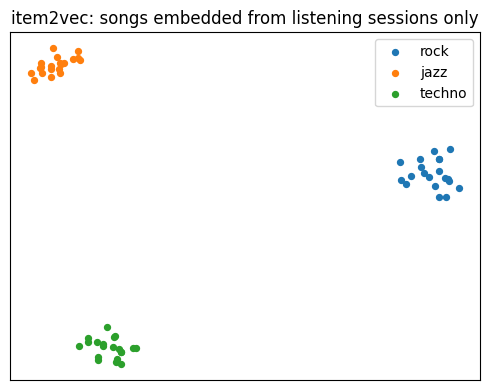

similar to song3: ['song12', 'song10', 'song16', 'song11', 'song4']


In [23]:
rng = np.random.default_rng(SEED)
genres = {"rock": range(0, 20), "jazz": range(20, 40), "techno": range(40, 60)}
genre_of = {i: g for g, r in genres.items() for i in r}
sessions = []
for _ in range(3000):
    g = rng.choice(list(genres))
    items = [int(rng.choice(genres[g])) if rng.random() < 0.85 else int(rng.integers(60)) for _ in range(rng.integers(5, 15))]
    sessions.append([f"song{i}" for i in items])
item2vec = Word2Vec(sessions, vector_size=16, window=3, min_count=1, sg=1, negative=5, epochs=10, seed=SEED, workers=1)
items = [f"song{i}" for i in range(60)]
xy = PCA(2).fit_transform(item2vec.wv[items])
plt.figure(figsize=(5, 4))
for k, g in enumerate(genres):
    sel = [i for i in range(60) if genre_of[i] == g]
    plt.scatter(xy[sel, 0], xy[sel, 1], color=f"C{k}", label=g, s=18)
plt.legend()
plt.title("item2vec: songs embedded from listening sessions only")
plt.xticks([])
plt.yticks([])
plt.tight_layout()
plt.show()
print("similar to song3:", [w for w, _ in item2vec.wv.most_similar("song3", topn=5)])

### Limits: word forms and one vector per word

**Czech and other inflected languages.** Word2vec treats every word form as a separate word: *Praha, Prahy, Praze,
Prahu, Prahou* get five unrelated vectors, each learned only from the occurrences of that one form, and a form
never seen in training gets no vector at all. **fastText** (Facebook, 2016) builds a word vector as the sum of vectors of its character n-grams,
so unseen forms share most pieces with known ones. Transformers solve the same problem with **subword
tokenisation** (section 5.1).

In [24]:
def char_ngrams(word, n_min=3, n_max=5):
    w = f"<{word}>"
    return [w[i:i + n] for n in range(n_min, n_max + 1) for i in range(len(w) - n + 1)]


forms = ["praha", "prahy", "praze", "prahu", "prahou"]
print("in GloVe vocabulary (400k words of English text):", {f: f in glove.key_to_index for f in forms})
shared = set(char_ngrams("praha")) & set(char_ngrams("prahou"))
print(f"character 3-5-grams of 'prahou': {len(char_ngrams('prahou'))}, shared with 'praha': {sorted(shared)}")

in GloVe vocabulary (400k words of English text): {'praha': True, 'prahy': False, 'praze': False, 'prahu': False, 'prahou': False}
character 3-5-grams of 'prahou': 15, shared with 'praha': ['<pr', '<pra', '<prah', 'pra', 'prah', 'rah']


**One vector per word.** *Bank* has one vector, whether the sentence is about a river or about money. It is a
compromise dominated by the more frequent meaning:

In [25]:
print("GloVe neighbours of 'bank':", [w for w, _ in glove.most_similar("bank", topn=8)])
for other in ["money", "loan", "river", "shore"]:
    print(f"cos(bank, {other}) = {glove.similarity('bank', other):.2f}")

GloVe neighbours of 'bank': ['banks', 'banking', 'credit', 'investment', 'financial', 'securities', 'lending', 'funds']
cos(bank, money) = 0.57
cos(bank, loan) = 0.55
cos(bank, river) = 0.33
cos(bank, shore) = 0.51


What we want is a vector of *bank* that depends on the rest of the sentence. That is exactly what a transformer
computes.

## 5. Transformers: one architecture, many models

The transformer (Vaswani et al., Google, *Attention Is All You Need*, 2017) was built for machine translation. Its
core is **self-attention**: every token looks at all other tokens and mixes their vectors into its own, so the
output vector of *bank* depends on the sentence. Stack a few dozen such layers, train on a huge amount of text, and
you get the models behind today's search engines, translators and chat assistants.

The pipeline of every text transformer:

**text → tokens → token embeddings (a table, like word2vec) + positions → N × [self-attention + small MLP] → contextual vectors → task head**

### 5.1 Tokenisation: subwords

Transformers do not use a fixed list of words. A **tokenizer** splits text into pieces from a vocabulary of
30 000 to 250 000 subwords learned from data, most often by **byte-pair encoding** (BPE, used by GPT, Llama,
Qwen): start with single characters and repeatedly merge the most frequent adjacent pair. BERT uses the similar
WordPiece (the `##` pieces below), XLM-RoBERTa the SentencePiece unigram method. Frequent words end up as one token,
rare words and word forms are split into pieces. Byte-level tokenizers (GPT-2, Qwen) can encode any text, so no
word is ever unknown.

In [26]:
def bpe_demo(words, n_merges=8):
    seqs = collections.Counter(tuple(w) + ("_",) for w in words)          # "_" marks the end of a word
    for step in range(1, n_merges + 1):
        pair_counts = collections.Counter()
        for seq, c in seqs.items():
            for a, b in zip(seq, seq[1:]):
                pair_counts[(a, b)] += c
        (a, b), c = pair_counts.most_common(1)[0]
        new = collections.Counter()
        for seq, cnt in seqs.items():
            out, k = [], 0
            while k < len(seq):
                if k + 1 < len(seq) and seq[k] == a and seq[k + 1] == b:
                    out.append(a + b)
                    k += 2
                else:
                    out.append(seq[k])
                    k += 1
            new[tuple(out)] += cnt
        seqs = new
        print(f"merge {step}: '{a}' + '{b}' (seen {c}x)  ->  " + "  ".join(" ".join(s) for s in list(seqs)[:6]))


bpe_demo(["praha"] * 5 + ["prahou"] * 3 + ["praze"] * 2 + ["prahy"] * 4 + ["brno"] * 3 + ["brnem"] * 2)

merge 1: 'p' + 'r' (seen 14x)  ->  pr a h a _  pr a h o u _  pr a z e _  pr a h y _  b r n o _  b r n e m _
merge 2: 'pr' + 'a' (seen 14x)  ->  pra h a _  pra h o u _  pra z e _  pra h y _  b r n o _  b r n e m _
merge 3: 'pra' + 'h' (seen 12x)  ->  prah a _  prah o u _  pra z e _  prah y _  b r n o _  b r n e m _
merge 4: 'prah' + 'a' (seen 5x)  ->  praha _  prah o u _  pra z e _  prah y _  b r n o _  b r n e m _
merge 5: 'praha' + '_' (seen 5x)  ->  praha_  prah o u _  pra z e _  prah y _  b r n o _  b r n e m _
merge 6: 'b' + 'r' (seen 5x)  ->  praha_  prah o u _  pra z e _  prah y _  br n o _  br n e m _
merge 7: 'br' + 'n' (seen 5x)  ->  praha_  prah o u _  pra z e _  prah y _  brn o _  brn e m _
merge 8: 'prah' + 'y' (seen 4x)  ->  praha_  prah o u _  pra z e _  prahy _  brn o _  brn e m _


Real tokenizers on the same sentence in English and in Czech. **Before running:** which tokenizer will need the most
tokens for the Czech sentence?

In [27]:
sentences = {"English": "The students are studying machine learning in Prague.",
             "Czech": "Studenti v Praze studují strojové učení."}
tokenizers = {
    "GPT-2 (2019, English)": "openai-community/gpt2",
    "BERT uncased (2018, English)": "google-bert/bert-base-uncased",
    "XLM-RoBERTa (2019, 100 languages)": "FacebookAI/xlm-roberta-base",
    "Qwen3.5 (2026, multilingual)": "Qwen/Qwen3.5-0.8B",
}
loaded_tokenizers = {name: AutoTokenizer.from_pretrained(repo) for name, repo in tokenizers.items()}


def show_tokens(texts):
    rows = []
    for name, tok in loaded_tokenizers.items():
        for lang, text in texts.items():
            ids = tok(text, add_special_tokens=False)["input_ids"]
            rows.append({"tokenizer": name, "text": lang, "tokens": len(ids),
                         "pieces": " | ".join(tok.decode([i]) for i in ids)})
    return pd.DataFrame(rows)


show_tokens(sentences)

,tokenizer,text,tokens,pieces
0,"GPT-2 (2019, English)",English,9,The | students | are | studying | machine | learning | in | Prague | .
1,"GPT-2 (2019, English)",Czech,17,Student | i | v | Pra | ze | stud | uj | í | stro | j | ov | é | u | č | en | í | .
2,"BERT uncased (2018, English)",English,9,the | students | are | studying | machine | learning | in | prague | .
3,"BERT uncased (2018, English)",Czech,16,student | ##i | v | pr | ##az | ##e | stud | ##uj | ##i | st | ##ro | ##jo | ##ve | uc | ##eni | .
4,"XLM-RoBERTa (2019, 100 languages)",English,10,The | students | are | study | ing | machine | learning | in | Prague | .
5,"XLM-RoBERTa (2019, 100 languages)",Czech,11,Student | i | v | Praze | stud | ují | stroj | ové | u | čení | .
6,"Qwen3.5 (2026, multilingual)",English,9,The | students | are | studying | machine | learning | in | Prague | .
7,"Qwen3.5 (2026, multilingual)",Czech,12,Student | i | v | Pra | ze | stud | ují | stroj | ové | uč | ení | .


- English tokenizers cut Czech into many short, meaningless pieces; uncased BERT even strips the diacritics
  (*učení* → *uceni*).
- Multilingual tokenizers keep Czech word stems together (*stud|ují*, *stroj|ové*).
- Token count matters in practice: models have a maximum context length and APIs charge per token, so the same
  text in Czech can cost noticeably more than in English with an English-centred tokenizer.

### 5.2 Self-attention by hand

For a sentence with token vectors $X \in \mathbb{R}^{n \times d}$ (one row per token), a self-attention layer
computes three projections, *queries* $Q = XW_Q$, *keys* $K = XW_K$ and *values* $V = XW_V$, and

$$\text{Attention}(Q, K, V) = \operatorname{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right) V,$$

where $d_k$ is the length of the key vectors.

Row $i$ of the softmax matrix says how much token $i$ looks at each other token; the output of token $i$ is the
corresponding weighted average of the value vectors. To see the mechanism without training anything, we take the
GloVe vectors as $X$ and identity projections ($W_Q = W_K = W_V = I$), so that the weights are just scaled
similarities. With $W = I$ every word would mostly look at itself, so for the demo we hide the diagonal, and as in
a real transformer we add the result back to the original vector (a *residual connection*):
new *bank* = GloVe *bank* + attention output. In a real transformer the three matrices are learned (so that, for
example, *the* does not attract attention just because it is frequent), and there are many attention "heads" in
parallel, each with its own matrices, in every layer.

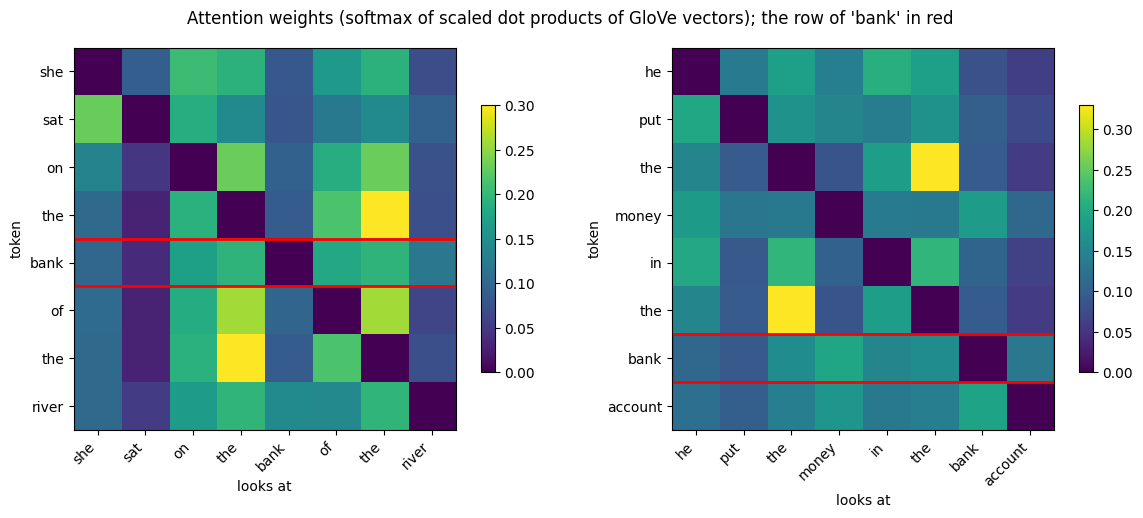

,vector of 'bank' in,cos with river,cos with money
0,"(static GloVe vector, no context)",0.33,0.57
1,she sat on the bank of the river,0.50,0.67
2,he put the money in the bank account,0.41,0.74


In [28]:
def self_attention(words, kv):
    X = np.stack([kv[w] for w in words])
    scores = X @ X.T / np.sqrt(X.shape[1])
    np.fill_diagonal(scores, -np.inf)                 # for the demo: look only at the other words
    weights = np.exp(scores - scores.max(1, keepdims=True))
    weights /= weights.sum(1, keepdims=True)
    return weights, weights @ X


s_river = ["she", "sat", "on", "the", "bank", "of", "the", "river"]
s_money = ["he", "put", "the", "money", "in", "the", "bank", "account"]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
outputs = {"(static GloVe vector, no context)": glove["bank"]}
for ax, s in zip(axes, [s_river, s_money]):
    weights, out = self_attention(s, glove)
    outputs[" ".join(s)] = glove["bank"] + out[s.index("bank")]          # residual connection
    im = ax.imshow(weights, cmap="viridis")
    plt.colorbar(im, ax=ax, shrink=0.7)
    ax.set_xticks(range(len(s)), s, rotation=45, ha="right")
    ax.set_yticks(range(len(s)), s)
    ax.set_xlabel("looks at")
    ax.set_ylabel("token")
    b = s.index("bank")
    ax.add_patch(plt.Rectangle((-0.5, b - 0.5), len(s), 1, fill=False, ec="red", lw=2))
fig.suptitle("Attention weights (softmax of scaled dot products of GloVe vectors); the row of 'bank' in red")
plt.tight_layout()
plt.show()

rows = []
for sent, v in outputs.items():
    rows.append({"vector of 'bank' in": sent, **{f"cos with {w}": float(unit(v) @ unit(glove[w])) for w in ["river", "money"]}})
pd.DataFrame(rows).round(2)

The static vector of *bank* is closer to *money* than to *river*. After one attention step the vector of *bank*
moves towards *river* in the river sentence and towards *money* in the money sentence (read the table by columns).
That is a **contextual** vector: same word, different vector depending on the sentence. A trained transformer
repeats this in dozens of layers with learned projections and many heads; the residual connections keep the
original word meaning and refine it rather than replace it.

**Positions.** Attention itself ignores word order (it is a weighted average over a set). The original transformer
and BERT/GPT-2 therefore **add a position vector** to each token vector: a fixed pattern of sines and cosines of
different frequencies (below), or a learned vector per position. Most models since 2021 (Llama, Qwen, Gemma,
Mistral, DeepSeek, ModernBERT) instead **rotate** the query and key vectors by an angle that grows with the
position (rotary position embedding, RoPE), so that attention scores depend on the relative distance of two tokens.

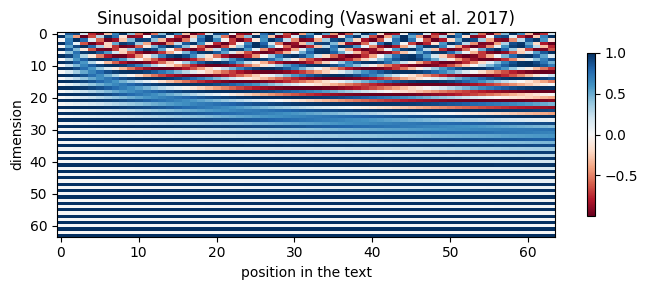

In [29]:
pos = np.arange(64)[:, None]
dim = np.arange(64)[None, :]
angle = pos / 10000 ** (2 * (dim // 2) / 64)
pe = np.where(dim % 2 == 0, np.sin(angle), np.cos(angle))
plt.figure(figsize=(7, 3))
plt.imshow(pe.T, aspect="auto", cmap="RdBu")
plt.xlabel("position in the text")
plt.ylabel("dimension")
plt.colorbar(shrink=0.8)
plt.title("Sinusoidal position encoding (Vaswani et al. 2017)")
plt.tight_layout()
plt.show()

### 5.3 Encoder, decoder, encoder-decoder

The 2017 transformer had two halves. Later models kept one or both, and the choice decides what a model is good
for. The difference is in **which tokens each token may attend to** (the attention mask) and in **what the model
is trained to predict**.

| | Encoder | Decoder | Encoder-decoder |
|---|---|---|---|
| attention | every token sees the whole input (bidirectional) | each token sees itself and the tokens before it (causal mask) | encoder bidirectional; decoder causal + attends to the encoder output (cross-attention) |
| training objective | fill in masked words (*masked language modelling*), later contrastive pairs | predict the next token | turn an input text into an output text (translation, denoising) |
| output | one contextual vector per token | the next token, one at a time | a new sequence |
| used for | embeddings, search, classification, named entities, reranking | text generation, chat, code, reasoning; today most "LLMs" | translation, summarisation, speech recognition (Whisper) |
| examples | BERT, RoBERTa, ModernBERT, the sentence models of Lecture 05 | GPT family, Llama, Qwen, Gemma, Mistral, DeepSeek | original Transformer, T5, BART, Whisper |

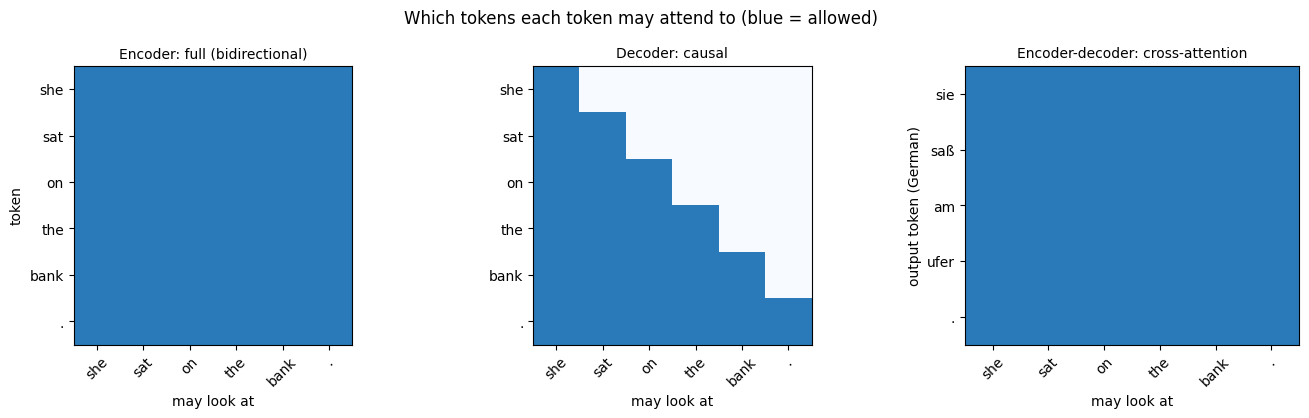

In [30]:
n = 6
tok_src = ["she", "sat", "on", "the", "bank", "."]
tok_tgt = ["sie", "saß", "am", "ufer", ".", ""]
masks = {
    "Encoder: full (bidirectional)": (np.ones((n, n)), tok_src, tok_src),
    "Decoder: causal": (np.tril(np.ones((n, n))), tok_src, tok_src),
    "Encoder-decoder: cross-attention": (np.ones((n - 1, n)), tok_tgt[:-1], tok_src),
}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (title, (m, rows_, cols_)) in zip(axes, masks.items()):
    ax.imshow(m, cmap="Blues", vmin=0, vmax=1.4)
    ax.set_xticks(range(len(cols_)), cols_, rotation=45)
    ax.set_yticks(range(len(rows_)), rows_)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("may look at")
axes[0].set_ylabel("token")
axes[2].set_ylabel("output token (German)")
fig.suptitle("Which tokens each token may attend to (blue = allowed)")
plt.tight_layout()
plt.show()

**The three families on the same sentence.** Three small models, one of each kind:

- **DistilBERT** (encoder, 66M parameters) fills in a masked word using both sides of the context,
- **DistilGPT-2** (decoder, 82M) predicts the next token from the left context only,
- **T5-small** (encoder-decoder, 60M) translates English to German.

**Before running:** how should T5 translate *bank* in the two sentences?

In [31]:
enc_name, dec_name, s2s_name = "distilbert/distilbert-base-uncased", "distilbert/distilgpt2", "google-t5/t5-small"
enc_tok = AutoTokenizer.from_pretrained(enc_name)
enc = AutoModelForMaskedLM.from_pretrained(enc_name, attn_implementation="eager").to(device).eval()
dec_tok = AutoTokenizer.from_pretrained(dec_name)
dec = AutoModelForCausalLM.from_pretrained(dec_name).to(device).eval()
s2s_tok = AutoTokenizer.from_pretrained(s2s_name)
s2s = AutoModelForSeq2SeqLM.from_pretrained(s2s_name).to(device).eval()


@torch.no_grad()
def fill_mask(text, k=5):
    x = enc_tok(text, return_tensors="pt").to(device)
    pos = (x.input_ids[0] == enc_tok.mask_token_id).nonzero()[0, 0]
    p = enc(**x).logits[0, pos].softmax(-1).topk(k)
    return ", ".join(f"{enc_tok.decode([int(i)]).strip()} {v:.2f}" for v, i in zip(p.values, p.indices))


@torch.no_grad()
def next_token(text, k=5):
    x = dec_tok(text, return_tensors="pt").to(device)
    p = dec(**x).logits[0, -1].softmax(-1).topk(k)
    return ", ".join(f"{dec_tok.decode([int(i)]).strip()} {v:.2f}" for v, i in zip(p.values, p.indices))


@torch.no_grad()
def translate(text):
    x = s2s_tok("translate English to German: " + text, return_tensors="pt").to(device)
    return s2s_tok.decode(s2s.generate(**x, max_new_tokens=40)[0], skip_special_tokens=True)


print("ENCODER  fill [MASK]   'she sat on the bank of the [MASK].'  ->", fill_mask("She sat on the bank of the [MASK]."))
print("ENCODER  fill [MASK]   'he deposited the money in the [MASK].' ->", fill_mask("He deposited the money in the [MASK]."))
print("DECODER  next token    'She sat on the bank of the'            ->", next_token("She sat on the bank of the"))
print("ENC-DEC  translation   'She sat on the bank of the river.'     ->", translate("She sat on the bank of the river."))
print("ENC-DEC  translation   'He deposited the money in the bank.'   ->", translate("He deposited the money in the bank."))

ENCODER  fill [MASK]   'she sat on the bank of the [MASK].'  -> river 0.24, thames 0.11, creek 0.04, seine 0.03, lake 0.02
ENCODER  fill [MASK]   'he deposited the money in the [MASK].' -> envelope 0.08, treasury 0.06, bank 0.06, vault 0.06, briefcase 0.02
DECODER  next token    'She sat on the bank of the'            -> river 0.02, bank 0.02, city 0.01, Bank 0.01, River 0.01


ENC-DEC  translation   'She sat on the bank of the river.'     -> Sie saß am Ufer des Flusses.
ENC-DEC  translation   'He deposited the money in the bank.'   -> Er hat das Geld in die Bank eingereicht.


T5 translates *bank* as *Ufer* (river bank) in one sentence and *Bank* (money) in the other: the encoder produced
different vectors for the same word. We can check that directly: the vectors of *bank* from the last layer of
DistilBERT in the two sentences, compared with word2vec, where it is one and the same vector.

The decoder is much less sure than the encoder: the best next token has a probability of a few percent. It sees
only the left context and does not know that the sentence ends after one more word, so *river*, *Thames*, *road* or
*city* are all plausible. How a decoder turns such distributions into fluent text is the topic of Lecture 07.

In [32]:
@torch.no_grad()
def contextual_vector(text, word):
    x = enc_tok(text, return_tensors="pt").to(device)
    hidden = enc(**x, output_hidden_states=True).hidden_states[-1][0]      # last layer, one vector per token
    return hidden[enc_tok.convert_ids_to_tokens(x.input_ids[0]).index(word)].cpu().numpy()


b_river = contextual_vector("She sat on the bank of the river.", "bank")
b_money = contextual_vector("He deposited the money in the bank.", "bank")
b_money2 = contextual_vector("The bank raised its interest rates.", "bank")
print(f"DistilBERT 'bank': river vs. money sentence {unit(b_river) @ unit(b_money):.2f}, "
      f"two money sentences {unit(b_money) @ unit(b_money2):.2f}")
print("word2vec  'bank': 1.00 in any two sentences (one vector per word)")

DistilBERT 'bank': river vs. money sentence 0.64, two money sentences 0.87
word2vec  'bank': 1.00 in any two sentences (one vector per word)


### 5.4 Attention inside a real model *(optional)*

DistilBERT has 6 layers with 12 heads each. Below: how much the token *bank* attends to each other token, averaged
over the heads, layer by layer, in the two sentences. Individual heads specialise (next word, previous word,
punctuation, the verb of a noun), and attention weights are a hint, not an explanation, of what the model does.

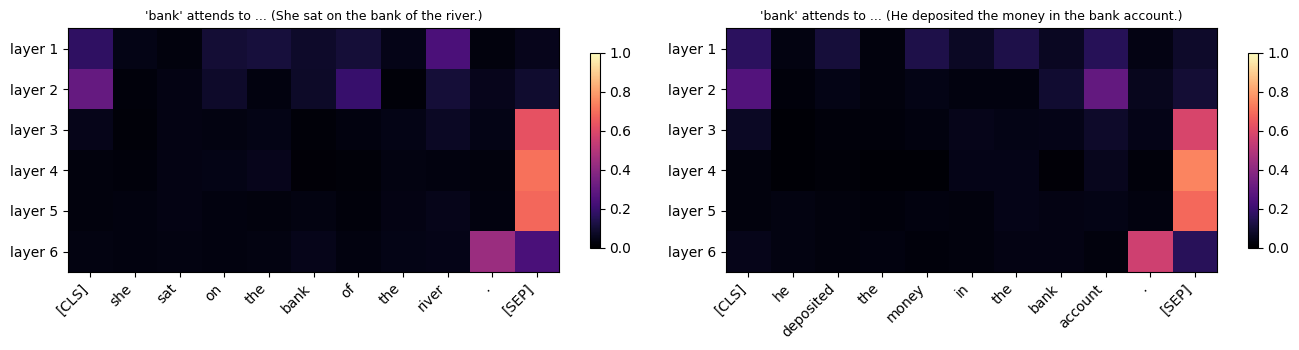

In [33]:
@torch.no_grad()
def word_attention(text, word="bank"):
    x = enc_tok(text, return_tensors="pt").to(device)
    att = enc(**x, output_attentions=True).attentions            # layers x (1, heads, n, n)
    toks = enc_tok.convert_ids_to_tokens(x.input_ids[0])
    b = toks.index(word)
    return toks, np.stack([a[0, :, b, :].mean(0).cpu().numpy() for a in att])


def plot_attention(texts, word="bank"):
    fig, axes = plt.subplots(1, len(texts), figsize=(6.8 * len(texts), 3.6), squeeze=False)
    for ax, text in zip(axes[0], texts):
        toks, m = word_attention(text, word)
        im = ax.imshow(m, cmap="magma", aspect="auto", vmin=0, vmax=1)
        ax.set_xticks(range(len(toks)), toks, rotation=45, ha="right")
        ax.set_yticks(range(m.shape[0]), [f"layer {k + 1}" for k in range(m.shape[0])])
        ax.set_title(f"'{word}' attends to ... ({text})", fontsize=9)
        plt.colorbar(im, ax=ax, shrink=0.8)
    plt.tight_layout()
    plt.show()


plot_attention(["She sat on the bank of the river.", "He deposited the money in the bank account."])

In the first layers *bank* looks at the informative words (*river*, *account*) and at `[CLS]`. In layers 3 to 5
almost all of the weight goes to the special token `[SEP]`, in the last layer to the full stop: heads use such
tokens as a "nothing to do here" default. Attention maps are therefore hard to read directly, which is one reason why they are a hint and not an
explanation.

### 5.5 History of the best-known transformers

Since 2017 the transformer has become the default architecture for text, then for images, speech, video, time
series and tables. Below are milestone models whose size has been published (almost all of them with open
weights), by year, by kind and by size. The large closed models (the GPT, Gemini and Claude families) publish no
parameter counts and no architecture details; we compare them in section 5.6 by what they can do on public
leaderboards.

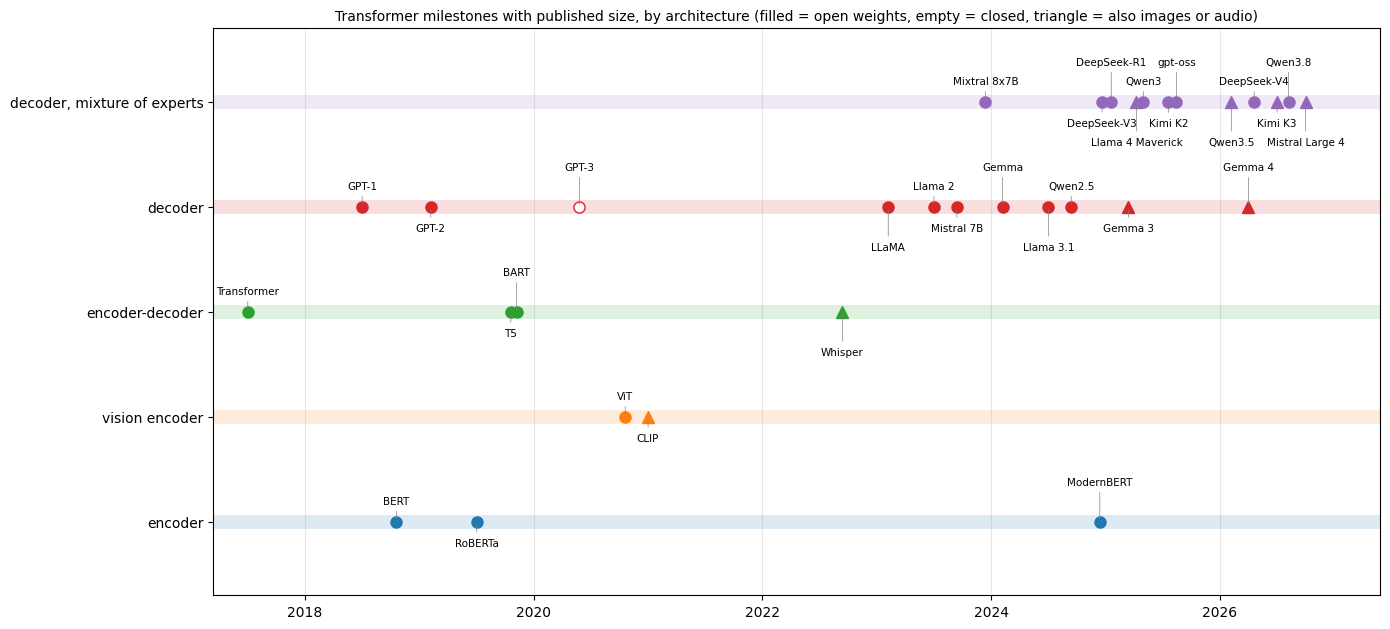

In [34]:
# (name, organisation, date as year + month/12, architecture, total parameters (B), active per token (B), open weights, multimodal)
models = [
    ("Transformer", "Google", 2017.5, "encoder-decoder", 0.213, None, True, False),
    ("GPT-1", "OpenAI", 2018.5, "decoder", 0.117, None, True, False),
    ("BERT", "Google", 2018.8, "encoder", 0.34, None, True, False),
    ("GPT-2", "OpenAI", 2019.1, "decoder", 1.5, None, True, False),
    ("RoBERTa", "Meta", 2019.5, "encoder", 0.355, None, True, False),
    ("T5", "Google", 2019.8, "encoder-decoder", 11, None, True, False),
    ("BART", "Meta", 2019.85, "encoder-decoder", 0.4, None, True, False),
    ("GPT-3", "OpenAI", 2020.4, "decoder", 175, None, False, False),
    ("ViT", "Google", 2020.8, "vision encoder", 0.632, None, True, False),
    ("CLIP", "OpenAI", 2021.0, "vision encoder", 0.428, None, True, True),
    ("Whisper", "OpenAI", 2022.7, "encoder-decoder", 1.55, None, True, True),
    ("LLaMA", "Meta", 2023.1, "decoder", 65, None, True, False),
    ("Llama 2", "Meta", 2023.5, "decoder", 70, None, True, False),
    ("Mistral 7B", "Mistral", 2023.7, "decoder", 7.3, None, True, False),
    ("Mixtral 8x7B", "Mistral", 2023.95, "decoder, mixture of experts", 46.7, 12.9, True, False),
    ("Gemma", "Google", 2024.1, "decoder", 7, None, True, False),
    ("Llama 3.1", "Meta", 2024.5, "decoder", 405, None, True, False),
    ("Qwen2.5", "Alibaba", 2024.7, "decoder", 72, None, True, False),
    ("ModernBERT", "Answer.AI, LightOn", 2024.95, "encoder", 0.395, None, True, False),
    ("DeepSeek-V3", "DeepSeek", 2024.97, "decoder, mixture of experts", 671, 37, True, False),
    ("DeepSeek-R1", "DeepSeek", 2025.05, "decoder, mixture of experts", 671, 37, True, False),
    ("Gemma 3", "Google", 2025.2, "decoder", 27, None, True, True),
    ("Llama 4 Maverick", "Meta", 2025.27, "decoder, mixture of experts", 400, 17, True, True),
    ("Qwen3", "Alibaba", 2025.33, "decoder, mixture of experts", 235, 22, True, False),
    ("Kimi K2", "Moonshot", 2025.55, "decoder, mixture of experts", 1000, 32, True, False),
    ("gpt-oss", "OpenAI", 2025.62, "decoder, mixture of experts", 117, 5.1, True, False),
    ("Qwen3.5", "Alibaba", 2026.1, "decoder, mixture of experts", 397, 17, True, True),
    ("Gemma 4", "Google", 2026.25, "decoder", 31, None, True, True),
    ("DeepSeek-V4", "DeepSeek", 2026.3, "decoder, mixture of experts", 1600, 49, True, False),
    ("Kimi K3", "Moonshot", 2026.5, "decoder, mixture of experts", 2800, 104, True, True),
    ("Qwen3.8", "Alibaba", 2026.6, "decoder, mixture of experts", 2400, 95, True, False),
    ("Mistral Large 4", "Mistral", 2026.75, "decoder, mixture of experts", 1000, 52, True, True),
]
history = pd.DataFrame(models, columns=["model", "organisation", "date", "architecture", "params_B", "active_B",
                                        "open_weights", "multimodal"])
archs = ["encoder", "vision encoder", "encoder-decoder", "decoder", "decoder, mixture of experts"]
arch_colour = {a: f"C{i}" for i, a in enumerate(archs)}

fig, ax = plt.subplots(figsize=(14, 6.4))
for lane, a in enumerate(archs):
    sub = history[history.architecture == a].sort_values("date")
    ax.axhline(lane, color=arch_colour[a], alpha=0.15, lw=10)
    last_x = {}                                   # labels in four rows around the lane, spread so they do not overlap
    for j, r in enumerate(sub.itertuples()):
        ax.plot(r.date, lane, "^" if r.multimodal else "o", color=arch_colour[a], ms=8,
                mfc=arch_colour[a] if r.open_weights else "white")
        dy = [0.2, -0.2, 0.38, -0.38][j % 4]
        x = max(r.date, last_x.get(dy, -1) + 0.45)
        last_x[dy] = x
        ax.annotate(r.model, (r.date, lane), xytext=(x, lane + dy), fontsize=7.5, ha="center", va="center",
                    arrowprops=dict(arrowstyle="-", color="grey", lw=0.5))
ax.set_yticks(range(len(archs)), archs)
ax.set_ylim(-0.7, len(archs) - 0.3)
ax.set_xlim(2017.2, 2027.4)
ax.set_title("Transformer milestones with published size, by architecture "
             "(filled = open weights, empty = closed, triangle = also images or audio)", fontsize=10)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

*(optional)* The same models by size. For mixture-of-experts models the empty marker below shows how many
parameters are active for each token, which largely decides the computation per token (all weights still have to
fit in memory).

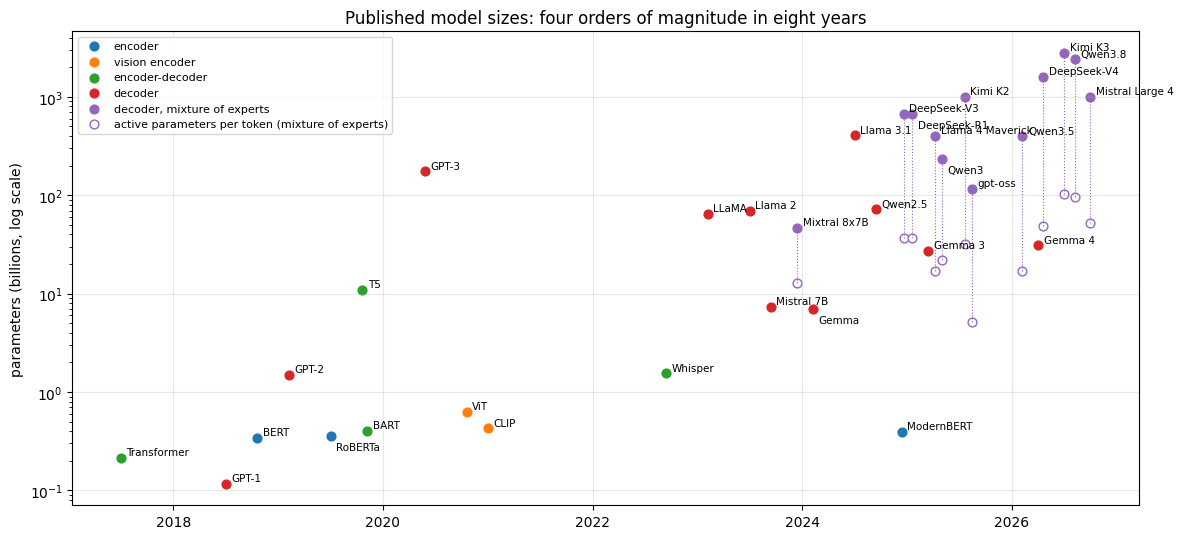

In [35]:
fig, ax = plt.subplots(figsize=(12, 5.5))
for a in archs:
    sub = history[history.architecture == a]
    ax.scatter(sub.date, sub.params_B, color=arch_colour[a], label=a, s=40)
moe = history.dropna(subset=["active_B"])
ax.scatter(moe.date, moe.active_B, facecolors="white", edgecolors=arch_colour["decoder, mixture of experts"], s=40,
           label="active parameters per token (mixture of experts)")
for r in moe.itertuples():
    ax.plot([r.date, r.date], [r.active_B, r.params_B], color=arch_colour["decoder, mixture of experts"], lw=0.8, ls=":")
for r in history.itertuples():
    ax.annotate(r.model, (r.date, r.params_B), fontsize=7.5, textcoords="offset points",
                xytext=(4, -10) if r.model in ("DeepSeek-R1", "RoBERTa", "Gemma", "Qwen3") else (4, 2))
ax.set_yscale("log")
ax.set_ylabel("parameters (billions, log scale)")
ax.set_title("Published model sizes: four orders of magnitude in eight years")
ax.legend(fontsize=8, loc="upper left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

A few turning points worth remembering:

- **2017-2019, two branches.** BERT (encoder) dominated understanding tasks and search, GPT (decoder) generation.
  T5 showed that every task can be phrased as text-to-text.
- **2020, scale.** GPT-3 (175B) could solve new tasks from a few examples in the prompt (*in-context learning*)
  without any fine-tuning. Model size grew by roughly 10x per year for a while.
- **2020-2022, beyond text.** ViT cut images into patches and treated them as tokens; CLIP (Lecture 05) trained an
  image encoder and a text encoder together; Whisper (2022) trained an encoder-decoder on 680 000 hours of
  transcribed audio.
- **2022, assistants.** Instruction tuning and reinforcement learning from human feedback turned a next-token
  predictor into a helpful chat model (ChatGPT).
- **2023 onwards, open weights.** LLaMA, Mistral, Qwen, Gemma and DeepSeek made strong models downloadable; much of
  the research and most student projects run on them.
- **Mixture of experts.** Very large recent models activate only a part of their parameters for each token (e.g.
  DeepSeek-V3: 671B in total, 37B per token), which makes them cheaper to run than their size suggests.
- **2024 onwards, reasoning.** Models trained to produce a long chain of intermediate steps before the answer (o1,
  DeepSeek-R1) improved maths and coding substantially.
- **Encoders are not dead.** Embedding models for search (Lecture 07 and 08), rerankers and classifiers are still
  mostly encoders, small and fast; ModernBERT (2024) refreshed the BERT recipe.

### 5.6 What the best models can do, compared with humans

The strongest models (the GPT, Gemini and Claude families) are closed: no weights, no size, no architecture. What
we can compare is what they do on public benchmarks. The plots show the **best score of any model available at
that date**, plotted against the model's release date, with human baselines where one exists. Each curve comes from
one source that re-ran the models with the same setup (mostly Epoch AI), so the points are comparable; many runs
were made later than the release (GPQA, for example, was published only in November 2023, after GPT-4). A benchmark
is usually "solved" within two or three years of its release, so new and harder ones keep appearing. ARC-AGI-3 is
scored differently from the others: 100 % means finishing all games as efficiently as the human testers.

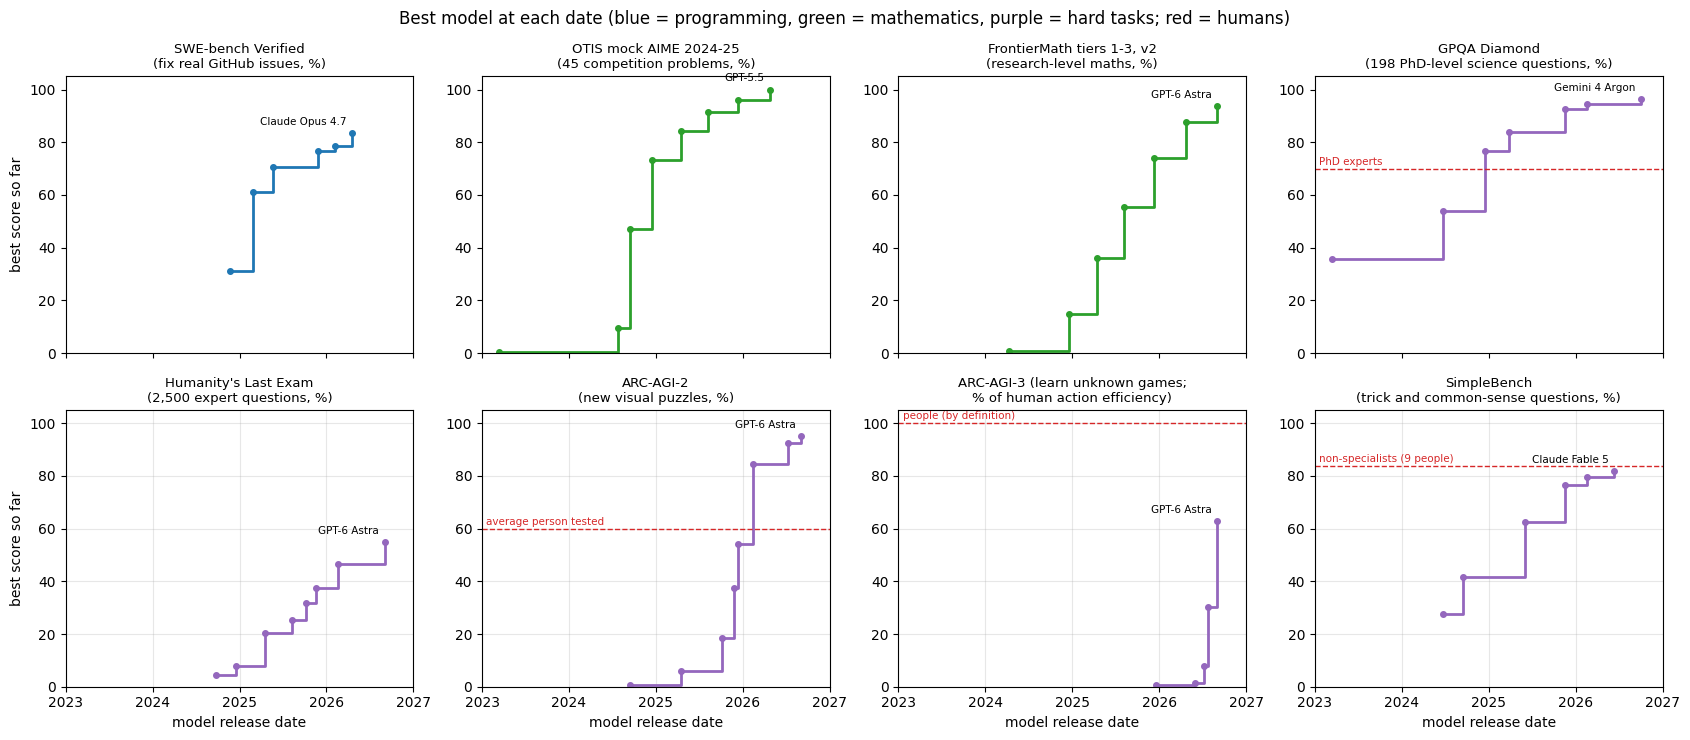

In [36]:
# Running best score by model release date: (release date, score, model). One source per benchmark, so that all
# points of a curve were measured the same way: Epoch AI Benchmarking Hub (epoch.ai/benchmarks, CC-BY, independent
# runs, data downloaded 6 Nov 2026) for SWE-bench, mock AIME, FrontierMath, GPQA, HLE, ARC-AGI-2 and SimpleBench;
# ARC Prize verified leaderboard (arcprize.org, standard harness) for ARC-AGI-3.
progress = {
    "SWE-bench Verified\n(fix real GitHub issues, %)": dict(
        data=[(2024.89, 31.0, "GPT-4o"), (2025.15, 61.0, "Claude 3.7 Sonnet"), (2025.39, 70.7, "Claude Opus 4"),
              (2025.9, 76.7, "Claude Opus 4.5"), (2026.1, 78.7, "Claude Opus 4.6"), (2026.29, 83.5, "Claude Opus 4.7")],
        humans=[], area="programming"),
    "OTIS mock AIME 2024-25\n(45 competition problems, %)": dict(
        data=[(2023.2, 0.6, "GPT-4"), (2024.56, 9.7, "Llama 3.1 405B"), (2024.7, 46.9, "o1-mini"), (2024.96, 73.3, "o1"),
              (2025.29, 84.4, "o3"), (2025.6, 91.4, "GPT-5"), (2025.94, 96.1, "GPT-5.2"), (2026.31, 100, "GPT-5.5")],
        humans=[], area="maths"),
    "FrontierMath tiers 1-3, v2\n(research-level maths, %)": dict(
        data=[(2024.27, 0.7, "GPT-4 Turbo"), (2024.96, 14.7, "o1"), (2025.29, 36.1, "o4-mini"), (2025.6, 55.4, "GPT-5"),
              (2025.94, 74.0, "GPT-5.2 Pro"), (2026.31, 87.7, "GPT-5.5 Pro"), (2026.67, 93.7, "GPT-6 Astra")],
        humans=[], area="maths"),
    "GPQA Diamond\n(198 PhD-level science questions, %)": dict(
        data=[(2023.2, 35.7, "GPT-4"), (2024.47, 54.0, "Claude 3.5 Sonnet"), (2024.96, 76.8, "o1"),
              (2025.23, 83.8, "Gemini 2.5 Pro"), (2025.88, 92.6, "Gemini 3 Pro"), (2026.13, 94.4, "Gemini 3.1 Pro"),
              (2026.75, 96.4, "Gemini 4 Argon")],
        humans=[(69.7, "PhD experts")], area="hard tasks"),
    "Humanity's Last Exam\n(2,500 expert questions, %)": dict(
        data=[(2024.73, 4.6, "Gemini 1.5 Pro"), (2024.96, 8.0, "o1"), (2025.29, 20.3, "o3"), (2025.6, 25.3, "GPT-5"),
              (2025.76, 31.6, "GPT-5 Pro"), (2025.88, 37.5, "Gemini 3 Pro"), (2026.13, 46.4, "Gemini 3.1 Pro"),
              (2026.67, 54.8, "GPT-6 Astra")],
        humans=[], area="hard tasks"),
    "ARC-AGI-2\n(new visual puzzles, %)": dict(
        data=[(2024.7, 0.8, "o1-mini"), (2025.29, 6.1, "o4-mini"), (2025.76, 18.3, "GPT-5 Pro"),
              (2025.9, 37.6, "Claude Opus 4.5"), (2025.94, 54.2, "GPT-5.2 Pro"), (2026.12, 84.6, "Gemini 3 Deep Think"),
              (2026.52, 92.5, "GPT-5.6 Sol"), (2026.67, 95.0, "GPT-6 Astra")],
        humans=[(60, "average person tested")], area="hard tasks"),
    "ARC-AGI-3 (learn unknown games;\n% of human action efficiency)": dict(
        data=[(2025.96, 0.5, "Claude Opus 4.6"), (2026.41, 1.5, "Claude Opus 4.8"), (2026.52, 7.8, "GPT-5.6 Sol"),
              (2026.56, 30.2, "Claude Opus 5"), (2026.67, 62.7, "GPT-6 Astra")],
        humans=[(100, "people (by definition)")], area="hard tasks"),
    "SimpleBench\n(trick and common-sense questions, %)": dict(
        data=[(2024.47, 27.5, "Claude 3.5 Sonnet"), (2024.7, 41.7, "o1-preview"), (2025.42, 62.4, "Gemini 2.5 Pro"),
              (2025.88, 76.4, "Gemini 3 Pro"), (2026.13, 79.6, "Gemini 3.1 Pro"), (2026.44, 81.9, "Claude Fable 5")],
        humans=[(83.7, "non-specialists (9 people)")], area="hard tasks"),
}
area_colour = {"programming": "tab:blue", "maths": "tab:green", "hard tasks": "tab:purple"}

fig, axes = plt.subplots(2, 4, figsize=(17, 7.5), sharex=True)
for ax, (name, b) in zip(axes.ravel(), progress.items()):
    d, v, m = zip(*b["data"])
    ax.step(d, v, where="post", color=area_colour[b["area"]], lw=2)
    ax.plot(d, v, "o", color=area_colour[b["area"]], ms=4)
    ax.annotate(m[-1], (d[-1], v[-1]), fontsize=7.5, xytext=(-4, 6), textcoords="offset points", ha="right")
    for level, who in b["humans"]:
        ax.axhline(level, color="tab:red", ls="--", lw=1)
        ax.text(2023.05, level + 1.5, who, fontsize=7.5, color="tab:red")
    ax.set_title(name, fontsize=9.5)
    ax.set_ylim(0, 105)
    ax.set_xlim(2023, 2027)
    ax.set_xticks([2023, 2024, 2025, 2026, 2027], ["2023", "2024", "2025", "2026", "2027"])
for ax in axes[1]:
    ax.set_xlabel("model release date")
    ax.grid(alpha=0.3)
for ax in axes[:, 0]:
    ax.set_ylabel("best score so far")
fig.suptitle("Best model at each date (blue = programming, green = mathematics, purple = hard tasks; red = humans)")
plt.tight_layout()
plt.show()

**How long a task can a model do on its own?** METR measures the length of software tasks (in the time a human
professional needs) that a model completes with 50 % success. It has doubled roughly every seven months since
2019, and faster since 2024. At 80 % success the horizon is several times shorter.

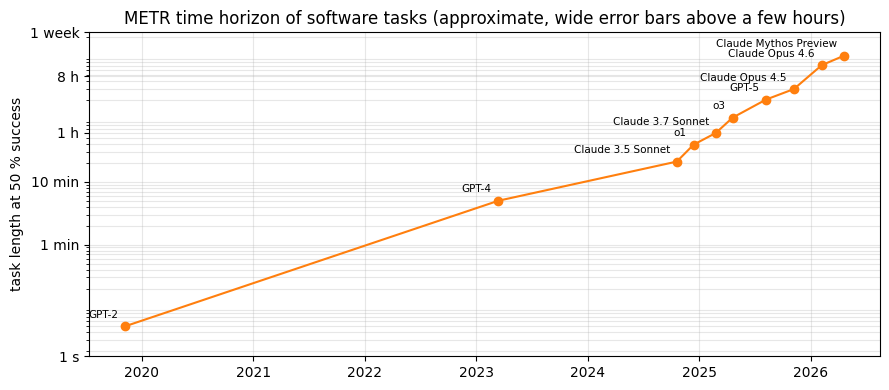

In [37]:
metr = [(2019.85, 0.05, "GPT-2"), (2023.2, 5, "GPT-4"), (2024.8, 21, "Claude 3.5 Sonnet"), (2024.95, 39, "o1"),
        (2025.15, 60, "Claude 3.7 Sonnet"), (2025.3, 105, "o3"), (2025.6, 204, "GPT-5"), (2025.85, 300, "Claude Opus 4.5"),
        (2026.1, 720, "Claude Opus 4.6"), (2026.3, 1020, "Claude Mythos Preview")]
d, minutes, m = zip(*metr)
fig, ax = plt.subplots(figsize=(9, 4))
ax.semilogy(d, minutes, "o-", color="tab:orange")
for x, y, name in metr:
    ax.annotate(name, (x, y), fontsize=7.5, xytext=(-5, 6), textcoords="offset points", ha="right")
ax.set_yticks([1 / 60, 1, 10, 60, 480, 2400], ["1 s", "1 min", "10 min", "1 h", "8 h", "1 week"])
ax.set_ylabel("task length at 50 % success")
ax.set_title("METR time horizon of software tasks (approximate, wide error bars above a few hours)")
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

**Already better than most humans (November 2026):**

| Area | Evidence |
|---|---|
| Competition programming | Codeforces rating 2724 (above 99.8 % of human competitors) already in early 2025; ICPC World Finals 2025 12/12 problems vs. 11/12 for the best human team |
| Competition maths | IMO 2025 gold medal (35/42, officially graded); mock AIME 100 % |
| Science questions | GPQA Diamond 96 % vs. 70 % for PhD experts in their own field |
| Research-level maths problems | FrontierMath tiers 1-3 94 %; teams of mathematicians in a 4.5-hour competition solved 19 % of a subset on average (35 % all teams together), not directly comparable |
| Static visual puzzles | ARC-AGI-1 98.5 % (people 77-98 %), ARC-AGI-2 95 % (average person 60 %) |

**Not yet, or only at human level:**

| Area | Evidence |
|---|---|
| Learning an unknown interactive environment efficiently | ARC-AGI-3 63 % of human efficiency, at a cost of tens of thousands of dollars for the test set |
| Long autonomous work | reliable (80 %) only on tasks of a few hours; METR estimates above a day are very uncertain |
| Trick questions and common sense | SimpleBench 82 % vs. 84 % for non-specialists |
| Genuinely open research problems | 3 of 68 unsolved Erdős problems (FrontierMath Erdős, one attempt per problem, October 2026) |
| Knowing what it does not know | Humanity's Last Exam 55 %, with confident wrong answers |

**How to read benchmark numbers.** Scores reported by the developers are usually higher than independent runs
(different prompts, tools, many attempts). Old benchmarks leak into training data (*contamination*, the leakage
of Lecture 03), and many have label errors (about 6 % of MMLU questions), so scores above ~90 % stop meaning much.
Benchmarks also get new versions (FrontierMath v2 corrected many problems in 2026), so compare numbers only within one
version and one source. Open-weight models trail the closed
frontier by roughly 6 to 12 months (e.g. GPQA Diamond 93 % vs. 96 %, ARC-AGI-2 78 % vs. 95 %).

### 5.7 State of the art by task (November 2026)

"Best model" changes every few weeks, so the table names families and points to the leaderboards that keep the
current ranking. Small open models in the last column run on a free Colab GPU.

In [38]:
sota = pd.DataFrame([
    ("Chat, text generation, reasoning", "decoder (often MoE, multimodal)",
     "Gemini, Claude, GPT families", "Qwen3.5, DeepSeek-V4, Kimi K3, Gemma 4, gpt-oss",
     "arena.ai/leaderboard/text, artificialanalysis.ai", "Qwen/Qwen3.5-0.8B; Qwen/Qwen3.5-2B; google/gemma-4-E2B-it"),
    ("Code", "decoder", "Claude, GPT, Gemini families", "Kimi K3, DeepSeek-V4, Qwen3.5",
     "arena.ai/leaderboard/webdev, SWE-bench", "Qwen/Qwen3.5-2B"),
    ("Text embeddings, search (RAG)", "bidirectional encoder, or a decoder trained for embeddings",
     "Gemini Embedding", "Qwen3-Embedding, BGE-M3, multilingual-E5, EmbeddingGemma, Harrier",
     "huggingface.co/spaces/mteb/leaderboard", "Qwen/Qwen3-Embedding-0.6B; microsoft/harrier-oss-v1-270m; BAAI/bge-m3; intfloat/multilingual-e5-small"),
    ("Reranking search results", "encoder (cross-encoder) or small decoder", "Cohere Rerank",
     "Qwen3-Reranker, BGE-reranker-v2-m3, mxbai-rerank-v2", "MTEB reranking tasks",
     "Qwen/Qwen3-Reranker-0.6B; BAAI/bge-reranker-v2-m3"),
    ("Text classification, entities", "encoder (fine-tuned)", "-",
     "ModernBERT, mmBERT, XLM-R, mDeBERTa; RobeCzech for Czech (non-commercial)", "task-specific benchmarks",
     "answerdotai/ModernBERT-base; jhu-clsp/mmBERT-small"),
    ("Machine translation", "decoder LLM or encoder-decoder", "Gemini, GPT, DeepL",
     "TranslateGemma, NLLB-200 (non-commercial)", "WMT shared tasks (statmt.org)", "google/translategemma-4b-it (gated)"),
    ("Speech recognition", "encoder-decoder, encoder + transducer, or encoder + LLM decoder", "-",
     "Whisper, Parakeet, Qwen3-ASR, Granite Speech", "hf-audio/open_asr_leaderboard",
     "openai/whisper-large-v3-turbo; nvidia/parakeet-tdt-0.6b-v3"),
    ("Image features, image-text search", "vision encoder (ViT)", "-",
     "DINOv3, SigLIP 2, Perception Encoder, CLIP", "linear-probe and retrieval benchmarks",
     "google/siglip2-base-patch16-224"),
    ("Image and video generation", "diffusion transformer", "GPT-Image, Gemini (Nano Banana), Veo",
     "FLUX.2, Qwen-Image, HunyuanImage, Wan 2.2", "arena.ai/leaderboard/text-to-image, text-to-video", "-"),
    ("Time-series forecasting", "decoder or encoder over patches of the series", "-",
     "TimesFM, Chronos-2, Moirai, Toto, TiRex", "Salesforce/GIFT-Eval",
     "amazon/chronos-bolt-small; google/timesfm-2.5-200m-pytorch"),
    ("Tabular data (classification, regression)", "transformer trained on synthetic tables (in-context learning)", "-",
     "TabPFN, TabICL, Mitra, TabFM, LimiX", "TabArena/leaderboard", "Prior-Labs/TabPFN-v2-clf (Prior Labs licence); jingang/TabICL"),
], columns=["task", "architecture", "closed (API)", "open weights", "where to check the ranking", "small, runs on Colab"])
sota.style.hide(axis="index").set_properties(**{"white-space": "normal", "text-align": "left", "font-size": "11px"})

task,architecture,closed (API),open weights,where to check the ranking,"small, runs on Colab"
"Chat, text generation, reasoning","decoder (often MoE, multimodal)","Gemini, Claude, GPT families","Qwen3.5, DeepSeek-V4, Kimi K3, Gemma 4, gpt-oss","arena.ai/leaderboard/text, artificialanalysis.ai",Qwen/Qwen3.5-0.8B; Qwen/Qwen3.5-2B; google/gemma-4-E2B-it
Code,decoder,"Claude, GPT, Gemini families","Kimi K3, DeepSeek-V4, Qwen3.5","arena.ai/leaderboard/webdev, SWE-bench",Qwen/Qwen3.5-2B
"Text embeddings, search (RAG)","bidirectional encoder, or a decoder trained for embeddings",Gemini Embedding,"Qwen3-Embedding, BGE-M3, multilingual-E5, EmbeddingGemma, Harrier",huggingface.co/spaces/mteb/leaderboard,Qwen/Qwen3-Embedding-0.6B; microsoft/harrier-oss-v1-270m; BAAI/bge-m3; intfloat/multilingual-e5-small
Reranking search results,encoder (cross-encoder) or small decoder,Cohere Rerank,"Qwen3-Reranker, BGE-reranker-v2-m3, mxbai-rerank-v2",MTEB reranking tasks,Qwen/Qwen3-Reranker-0.6B; BAAI/bge-reranker-v2-m3
"Text classification, entities",encoder (fine-tuned),-,"ModernBERT, mmBERT, XLM-R, mDeBERTa; RobeCzech for Czech (non-commercial)",task-specific benchmarks,answerdotai/ModernBERT-base; jhu-clsp/mmBERT-small
Machine translation,decoder LLM or encoder-decoder,"Gemini, GPT, DeepL","TranslateGemma, NLLB-200 (non-commercial)",WMT shared tasks (statmt.org),google/translategemma-4b-it (gated)
Speech recognition,"encoder-decoder, encoder + transducer, or encoder + LLM decoder",-,"Whisper, Parakeet, Qwen3-ASR, Granite Speech",hf-audio/open_asr_leaderboard,openai/whisper-large-v3-turbo; nvidia/parakeet-tdt-0.6b-v3
"Image features, image-text search",vision encoder (ViT),-,"DINOv3, SigLIP 2, Perception Encoder, CLIP",linear-probe and retrieval benchmarks,google/siglip2-base-patch16-224
Image and video generation,diffusion transformer,"GPT-Image, Gemini (Nano Banana), Veo","FLUX.2, Qwen-Image, HunyuanImage, Wan 2.2","arena.ai/leaderboard/text-to-image, text-to-video",-
Time-series forecasting,decoder or encoder over patches of the series,-,"TimesFM, Chronos-2, Moirai, Toto, TiRex",Salesforce/GIFT-Eval,amazon/chronos-bolt-small; google/timesfm-2.5-200m-pytorch


Time series and tabular foundation models return in Lecture 09, embedding models and rerankers in Lectures 07 and
08. Before choosing a model for your project, check the current leaderboard, the licence (several strong models
are non-commercial or gated), the size, and test it on *your* data: a leaderboard average is no guarantee for a
Czech text about a specific domain. *Gated* models need you to accept the licence on the model page and to set
`HF_TOKEN` in the Colab secrets (the key icon on the left).

### Your turn
1. Tokenise a sentence from your project with `show_tokens({"mine": "..."})`.
2. Try `fill_mask`, `next_token` and `translate` on your own sentences. Where does the 82M decoder go wrong?
3. Look at the attention of another word with `plot_attention(["..."], word="...")` (lower-case, one token).

In [39]:
print(fill_mask("The capital of the Czech Republic is [MASK]."))
print(next_token("The capital of the Czech Republic is"))
print(translate("The capital of the Czech Republic is Prague."))
show_tokens({"mine": "Praha je hlavní město České republiky."})

prague 0.81, brno 0.18, bratislava 0.00, sparta 0.00, pest 0.00
the 0.12, home 0.08, a 0.07, now 0.05, known 0.03
Die Hauptstadt der Tschechischen Republik ist Prag.


,tokenizer,text,tokens,pieces
0,"GPT-2 (2019, English)",mine,23,P | ra | ha | je | h | lav | n | í | m | � | � | st | o | � | � | es | k | é | rep | ub | lik | y | .
1,"BERT uncased (2018, English)",mine,15,pr | ##aha | je | h | ##lav | ##ni | me | ##sto | ce | ##ske | rep | ##ub | ##lik | ##y | .
2,"XLM-RoBERTa (2019, 100 languages)",mine,7,Praha | je | hlavní | město | České | republiky | .
3,"Qwen3.5 (2026, multilingual)",mine,10,Pra | ha | je | hlavní | mě | sto | České | republik | y | .


## 6. Summary and what comes next

- **An embedding layer is a table** (one-hot × matrix). Word2vec fills it by predicting context words, with
  negative sampling instead of a softmax over the vocabulary; the same contrastive idea as CLIP.
- **For analogies, more text beats a cleverer algorithm**: 2M → 17M words → 6B words (GloVe). On a real task
  (Quora duplicates) the ranking can differ: always evaluate on your own task.
- Static vectors are cheap and reusable (features, query expansion, item2vec for recommendations) but have **one
  vector per word form**: no context, no unseen forms, weak sentence vectors.
- **Transformers** split text into subword tokens, add positions and let tokens exchange information by
  **self-attention**, which gives contextual vectors.
- **Encoder** (bidirectional, embeddings, search, classification), **decoder** (causal, generation, today's LLMs),
  **encoder-decoder** (translation, speech). Pick the family by the task, the model by a current leaderboard and
  your own test.

**When is word2vec / fastText enough?** Small domain-specific corpus, very fast or offline inference, item
embeddings for recommendations, or as a baseline. For search, question answering and anything where context
matters, use a transformer.

**Lecture 07:** BERT vs. GPT in detail, how text is generated (temperature, top-p), contextual and sentence
embeddings, fine-tuning a small transformer on your data, semantic search with a measurable quality.
**Lecture 08:** retrieval-augmented generation (RAG) end to end.

### References
- T. Mikolov et al. (2013): *Efficient Estimation of Word Representations in Vector Space* and *Distributed
  Representations of Words and Phrases and their Compositionality* (word2vec, negative sampling).
- J. Pennington, R. Socher, C. Manning (2014): *GloVe: Global Vectors for Word Representation*.
- P. Bojanowski et al. (2017): *Enriching Word Vectors with Subword Information* (fastText).
- A. Vaswani et al. (2017): *Attention Is All You Need*.
- J. Devlin et al. (2018): *BERT*; A. Radford et al. (2019): *Language Models are Unsupervised Multitask Learners* (GPT-2);
  C. Raffel et al. (2019): *T5*.
- J. Alammar: *The Illustrated Word2vec* and *The Illustrated Transformer* (jalammar.github.io).
- Hugging Face LLM course: huggingface.co/learn/llm-course.
- Epoch AI, *Benchmarking Hub* (epoch.ai/benchmarks); ARC Prize (arcprize.org); METR, *Measuring AI ability to
  complete long tasks* (metr.org); D. Rein et al. (2023): *GPQA*; L. Phan et al. (2025): *Humanity's Last Exam*.
- A. Karpathy: *Let's build GPT: from scratch, in code, spelled out* (YouTube).